# 03 — Diagnostic Analytics (Analisis Diagnostik Risiko Gagal Bayar & Pengembalian Pinjaman Bondora)

## Tujuan
1. **Mengurangi Bias Seleksi Horizon Umur Pinjaman (*Right-Censoring* & Tenor):** Mengevaluasi dan membandingkan label gagal bayar berhorizon tetap **12 bulan (`default_12m`)** sebagai target diagnostik utama dan **24 bulan (`default_24m`)** sebagai uji sensitivitas terhadap label *resolved lifetime* (`default`) dari Tahap 2.
2. **Segmentasi Risiko pada Horizon Setara:** Memetakan profil tingkat gagal bayar 12 bulan dan 24 bulan beserta interval kepercayaan Wilson 95% dan bobot nominal (`Amount`) pada segmen geografis, riwayat kredit, demografi, dan kelompok tenor, terpisah dari kolom referensi non-fitur (`Rating`, `Interest_group`, `Gender`).
3. **Evaluasi Benchmark Internal Bondora:** Membandingkan rata-rata `ProbabilityOfDefault` (estimasi 1 tahun Bondora) dengan tingkat gagal bayar 12 bulan teramati (`default_12m`) per kelas `Rating` dan `ModelVersion`, serta menghitung ROC-AUC benchmark beserta interval kepercayaan *bootstrap* 95%.
4. **Uji Hipotesis & Peringkat Pendorong Eksploratif:** Melakukan uji Chi-square (kategorikal, ukuran efek Cramér's V terkoreksi bias) dan Mann–Whitney U (numerik, ukuran efek AUC univariat) dengan koreksi uji berganda **Holm–Bonferroni (`p_holm`)**, serta menghitung **Information Value (IV)** keseluruhan dan per era (`2009–2017` vs `2018–2020`).
5. **Korelasi, Multikolinearitas (VIF), dan Stabilitas Antar-Era (PSI):** Mengidentifikasi pasangan fitur numerik berkorelasi tinggi ($|\rho_s| \ge 0{,}80$), menghitung *Variance Inflation Factor* (VIF), dan mengukur pergeseran distribusi fitur antar-era menggunakan *Population Stability Index* (PSI).
6. **Analisis Waktu-ke-Default (Kaplan–Meier) & Transparansi Keadilan (*Fairness*):** Mengestimasi kurva insiden kumulatif gagal bayar $1 - S(t)$ hingga 36 bulan dengan uji *log-rank* terkoreksi Holm, serta mengevaluasi asosiasi deskriptif `Gender` terhadap `default_12m` dan kovariat geografis (`Country`).

> **Catatan Metodologis Penting:**
> - **Asosiasi bukan kausalitas:** Seluruh temuan pada buku catatan ini bersifat observasional/asosiatif (*"berasosiasi dengan"*, *"tercatat lebih tinggi pada"*), bukan hubungan sebab-akibat.
> - **Peringatan Peringkat Fitur Eksploratif:** Peringkat fitur (IV dan AUC univariat) dihitung pada seluruh populasi teramati untuk tujuan pemahaman diagnostik dan **tidak boleh dipakai langsung untuk pemilihan fitur di Tahap 4**. Pada Tahap 4, pemilihan fitur wajib dihitung ulang **hanya pada data latih (*training set*)** setelah pembagian data untuk mencegah kebocoran informasi (*data leakage*).

## Input / Output
- **Input:** `data/processed/bondora_clean.parquet` (`179.235 baris × 130 kolom`), `data/processed/schema.json`, `reports/tables/02_outcome_by_year.csv`, `reports/tables/02_default_rate_by_segment.csv`.
- **Output Tabel (`reports/tables/`):**
  - `03_horizon_label_summary.csv`, `03_default_rate_horizon_by_segment.csv`, `03_rating_vs_observed_12m.csv`, `03_benchmark_auc.csv`, `03_hypothesis_tests.csv`, `03_driver_ranking.csv`, `03_return_ratio_drivers.csv`, `03_high_correlation_pairs.csv`, `03_vif.csv`, `03_psi_by_era.csv`, `03_km_cumulative_default.csv`, `03_fairness_summary.csv`.
- **Output Grafik (`reports/figures/`):**
  - `03_horizon_default_rate_by_year.png`, `03_default_rate_horizon_utama.png`, `03_default_rate_horizon_tenor_dan_demografi.png`, `03_rating_pd_vs_observed_12m.png`, `03_driver_ranking_iv.png`, `03_correlation_heatmap.png`, `03_psi_by_era.png`, `03_km_country_and_rating.png`, `03_km_tenor_and_cohort.png`.


In [1]:
import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=FutureWarning)

# Add project root to sys.path so the src package can be imported
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import src.config as config
from src.utils.plotting import set_style, fmt_id

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

df = pd.read_parquet(config.DATA_PROCESSED / "bondora_clean.parquet")
with open(config.DATA_PROCESSED / "schema.json", "r", encoding="utf-8") as f:
    schema_meta = json.load(f)

print(f"Project root        : {config.PROJECT_ROOT}")
print(f"REPORT_DATE         : {config.REPORT_DATE}")
print(f"Dimensi dataset     : {fmt_id(df.shape[0])} baris x {df.shape[1]} kolom")
print(f"default.notna().sum : {fmt_id(int(df['default'].notna().sum()))}")
print(f"default.sum()       : {fmt_id(int(df['default'].sum()))}")
print(f"Jumlah fitur (Y)    : {schema_meta['n_features_Y']} fitur kandidat (3 indikator *_missing berstatus proxy_era)")

assert df.shape == (179_235, 130)
assert int(df["default"].notna().sum()) == 113_560
assert int(df["default"].sum()) == 71_864
assert schema_meta["n_features_Y"] == 44


Project root        : C:\Tugas-3-Pemodelan-Data\bondora-analytics
REPORT_DATE         : 2021-07-20
Dimensi dataset     : 179.235 baris x 130 kolom
default.notna().sum : 113.560
default.sum()       : 71.864
Jumlah fitur (Y)    : 44 fitur kandidat (3 indikator *_missing berstatus proxy_era)


---
## Bagian A — Verifikasi Label Horizon Tetap (`12m`, `24m`) & Efek Bias Seleksi

Pada Tahap 2, evaluasi menggunakan target `default` pada subset *resolved* (`is_resolved == True`, $n = 113.560$) menghadapi bias seleksi waktu pengamatan (*right-censoring*): pinjaman bertenor panjang (36–60 bulan) dari kohort 2017–2020 yang belum jatuh tempo hingga tanggal potong `REPORT_DATE = 2021-07-20` hanya masuk ke dalam subset *resolved* apabila mengalami gagal bayar lebih awal atau dilunasi dipercepat, sedangkan pinjaman yang masih berjalan lancar berstatus `Current` (tersensor).

Untuk menyamakan jendela pengamatan lintas kohort dan kelompok tenor, dibangun label gagal bayar berhorizon tetap $H \in \{12, 24\}$ bulan:
- **`observable_{H}m` (`bool`):** Bernilai `True` apabila `LoanDate + DateOffset(months=H) <= REPORT_DATE` (`2021-07-20`).
- **`default_{H}m` (`Int8` nullable):**
  - `NA` apabila `observable_{H}m == False`, **atau** pinjaman berstatus `Repaid` tanpa `DefaultDate` yang dilabeli default karena *write-off* pokok (`default == 1` tetapi `DefaultDate` kosong, sebanyak 448 baris di seluruh portofolio karena waktu gagal bayarnya tidak tercatat), **atau** `DefaultDate < LoanDate` (anomali tanggal).
  - `1` apabila `DefaultDate` tercatat dan `DefaultDate <= LoanDate + DateOffset(months=H)`.
  - `0` apabila pinjaman telah teramati penuh selama $H$ bulan dan tidak mengalami gagal bayar dalam $H$ bulan pertama (termasuk pinjaman yang lunas maupun pinjaman yang baru gagal bayar setelah bulan ke-$H$).

=== Validasi Waktu Gagal Bayar (DefaultDate - LoanDate) ===
Pinjaman dengan DefaultDate terisi : 71.416
Baris dengan DefaultDate < LoanDate: 0 baris
Distribusi (hari)                  : min=49, p25=166, median=292, mean=372.29, p75=480, max=2922
Pinjaman Repaid write-off tanpa DefaultDate (seluruh data): 448 baris (termasuk observable_12m: 414, observable_24m: 149)


,Horizon / Target,Populasi Teramati (observable=True),Valid Non-NA,Default (=1),Non-Default (=0),NA (Tersensor / Dikecualikan),Default Rate (%)
0,Horizon 12 Bulan (default_12m),148783,148369,43117,105252,30866,29.06
1,Horizon 24 Bulan (default_24m),98027,97878,44584,53294,81357,45.55
2,Resolved Lifetime Tahap 2 (default),113560,113560,71864,41696,65675,63.28


,loan_year,n_total,n_observable_12m,n_valid_12m,n_default_12m,rate_12m,n_observable_24m,n_valid_24m,n_default_24m,rate_24m,n_resolved_lifetime,n_default_lifetime,rate_resolved_lifetime,selisih_12m_vs_resolved,selisih_24m_vs_resolved
0,2009,665,665,665,181,0.272180,665,665,225,0.338346,665,259,0.389474,-0.117293,-0.051128
1,2010,1157,1157,1157,275,0.237684,1157,1157,397,0.343129,1157,437,0.377701,-0.140017,-0.034572
2,2011,451,451,451,62,0.137472,451,451,97,0.215078,451,125,0.277162,-0.139690,-0.062084
3,2012,457,457,457,33,0.072210,457,457,66,0.144420,456,95,0.208333,-0.136123,-0.063913
4,2013,2512,2512,2512,291,0.115844,2512,2512,585,0.232882,2481,887,0.357517,-0.241673,-0.124635
5,2014,7455,7455,7455,2115,0.283702,7455,7455,3231,0.433400,7324,4096,0.559257,-0.275555,-0.125857
6,2015,8046,8046,8043,2590,0.322019,8046,8043,3811,0.473828,7771,4863,0.625788,-0.303769,-0.151960
7,2016,10514,10514,10512,3634,0.345700,10514,10512,5226,0.497146,9905,6251,0.631095,-0.285395,-0.133949
8,2017,17933,17933,17924,6547,0.365264,17933,17924,9052,0.505021,15757,10531,0.668338,-0.303073,-0.163317
9,2018,25103,25103,25055,6774,0.270365,25103,25055,10592,0.422750,18906,12266,0.648789,-0.378424,-0.226039


=== Tabel Sebelum vs Sesudah menurut Kelompok Tenor (LoanDuration_group) ===


,segmen,n_resolved_lifetime,n_default_lifetime,rate_lifetime_pct,n_valid_12m,n_default_12m,rate_12m_pct,n_valid_24m,n_default_24m,rate_24m_pct,Perubahan 12m vs Lifetime (pp)
0,<= 12 bulan,7424,2041,27.49,7137,1570,22.00,6109,1844,30.18,-5.49
1,13–24 bulan,7428,2722,36.65,8315,1549,18.63,6620,2091,31.59,-18.02
2,25–36 bulan,36114,23551,65.21,50734,14432,28.45,33617,15462,45.99,-36.77
3,37–59 bulan,8207,5465,66.59,10254,3258,31.77,7804,3891,49.86,-34.82
4,60 bulan,54387,38085,70.03,71929,22308,31.01,43728,21296,48.70,-39.01
5,Total,113560,71864,63.28,148369,43117,29.06,97878,44584,45.55,-34.22


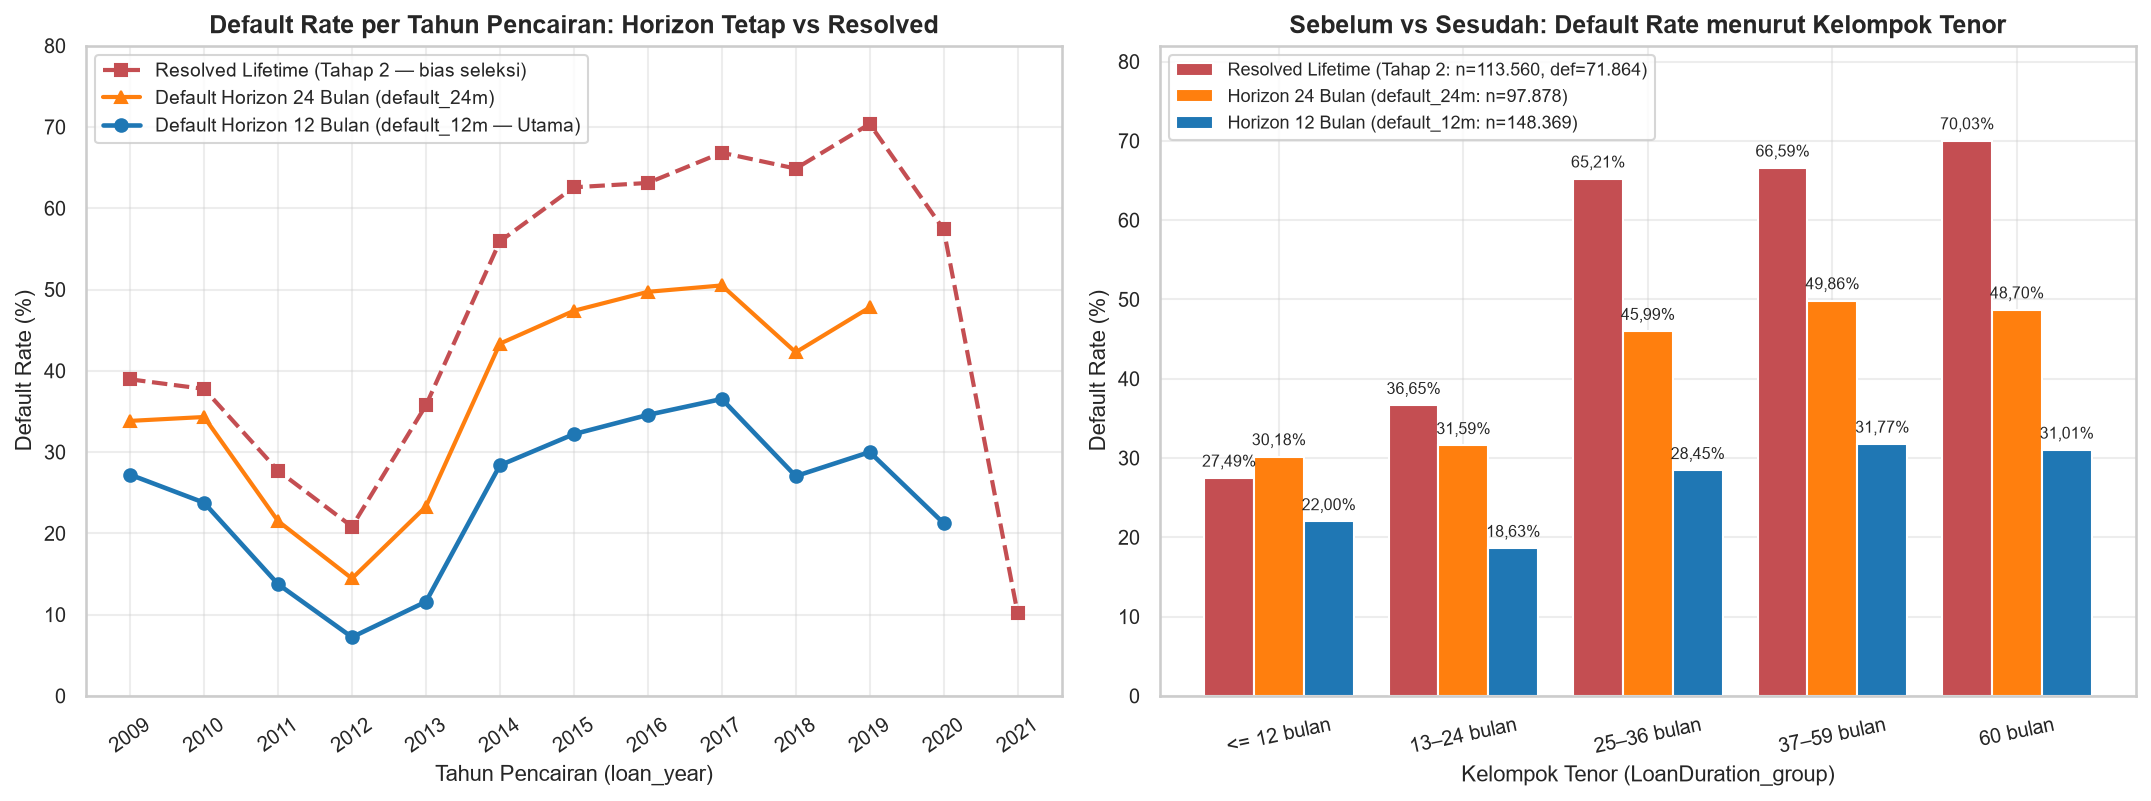

In [2]:
# 1. Validasi selisih hari DefaultDate - LoanDate dan ringkasan label horizon
has_dd = df["DefaultDate"].notna() & df["LoanDate"].notna()
diff_days = (df.loc[has_dd, "DefaultDate"] - df.loc[has_dd, "LoanDate"]).dt.days
n_neg_dd = int((diff_days < 0).sum())
repaid_wo = (df["Status"] == "Repaid") & df["DefaultDate"].isna() & (df["default"] == 1)

print("=== Validasi Waktu Gagal Bayar (DefaultDate - LoanDate) ===")
print(f"Pinjaman dengan DefaultDate terisi : {fmt_id(int(has_dd.sum()))}")
print(f"Baris dengan DefaultDate < LoanDate: {n_neg_dd} baris")
print(
    f"Distribusi (hari)                  : min={diff_days.min()}, p25={int(diff_days.quantile(0.25))}, "
    f"median={int(diff_days.median())}, mean={diff_days.mean():.2f}, p75={int(diff_days.quantile(0.75))}, max={diff_days.max()}"
)
print(
    f"Pinjaman Repaid write-off tanpa DefaultDate (seluruh data): {fmt_id(int(repaid_wo.sum()))} baris "
    f"(termasuk observable_12m: {fmt_id(int((repaid_wo & df['observable_12m']).sum()))}, "
    f"observable_24m: {fmt_id(int((repaid_wo & df['observable_24m']).sum()))})"
)

horizon_overview = pd.DataFrame([
    {
        "Horizon / Target": "Horizon 12 Bulan (default_12m)",
        "Populasi Teramati (observable=True)": int(df["observable_12m"].sum()),
        "Valid Non-NA": int(df["default_12m"].notna().sum()),
        "Default (=1)": int((df["default_12m"] == 1).sum()),
        "Non-Default (=0)": int((df["default_12m"] == 0).sum()),
        "NA (Tersensor / Dikecualikan)": int(df["default_12m"].isna().sum()),
        "Default Rate (%)": round(float(df["default_12m"].mean()) * 100, 2),
    },
    {
        "Horizon / Target": "Horizon 24 Bulan (default_24m)",
        "Populasi Teramati (observable=True)": int(df["observable_24m"].sum()),
        "Valid Non-NA": int(df["default_24m"].notna().sum()),
        "Default (=1)": int((df["default_24m"] == 1).sum()),
        "Non-Default (=0)": int((df["default_24m"] == 0).sum()),
        "NA (Tersensor / Dikecualikan)": int(df["default_24m"].isna().sum()),
        "Default Rate (%)": round(float(df["default_24m"].mean()) * 100, 2),
    },
    {
        "Horizon / Target": "Resolved Lifetime Tahap 2 (default)",
        "Populasi Teramati (observable=True)": int(df["is_resolved"].sum()),
        "Valid Non-NA": int(df["default"].notna().sum()),
        "Default (=1)": int((df["default"] == 1).sum()),
        "Non-Default (=0)": int((df["default"] == 0).sum()),
        "NA (Tersensor / Dikecualikan)": int(df["default"].isna().sum()),
        "Default Rate (%)": round(float(df["default"].mean()) * 100, 2),
    },
])
display(horizon_overview)

# 2. Tabel per loan_year: 03_horizon_label_summary.csv
tbl_horizon_year = pd.read_csv(config.TABLES_DIR / "03_horizon_label_summary.csv")
display(tbl_horizon_year)

# 3. Tabel sebelum vs sesudah untuk kelompok tenor (LoanDuration_group)
# Hitung ulang langsung dari kolom `default` dan LoanDuration_group (5 kelompok yang sama)
tenor_bins = [-np.inf, 12, 24, 36, 59, np.inf]
tenor_order = ["<= 12 bulan", "13–24 bulan", "25–36 bulan", "37–59 bulan", "60 bulan"]
df["LoanDuration_group"] = pd.cut(df["LoanDuration"], bins=tenor_bins, labels=tenor_order)

df_res_tenor = df[df["default"].notna()].copy()
tenor_t2 = (
    df_res_tenor.groupby("LoanDuration_group", observed=False)
    .agg(
        n_resolved_lifetime=("default", "count"),
        n_default_lifetime=("default", lambda s: int(s.sum())),
        rate_lifetime=("default", lambda s: float(s.astype(float).mean())),
    )
    .reindex(tenor_order)
    .reset_index()
    .rename(columns={"LoanDuration_group": "segmen"})
)

# Assert jumlah n = 113.560 dan jumlah default = 71.864 serta kesesuaian dengan 02_default_rate_by_segment.csv
assert int(tenor_t2["n_resolved_lifetime"].sum()) == 113_560, "Jumlah n resolved lifetime harus 113.560"
assert int(tenor_t2["n_default_lifetime"].sum()) == 71_864, "Jumlah default lifetime harus 71.864"

seg_t2_csv = pd.read_csv(config.TABLES_DIR / "02_default_rate_by_segment.csv")
seg_t2_tenor = seg_t2_csv[seg_t2_csv["variabel"] == "LoanDuration_group"].set_index("segmen").reindex(tenor_order)
assert (tenor_t2["n_resolved_lifetime"].to_numpy() == seg_t2_tenor["n"].to_numpy()).all()
assert (tenor_t2["n_default_lifetime"].to_numpy() == seg_t2_tenor["n_default"].to_numpy()).all()

seg_t3 = pd.read_csv(config.TABLES_DIR / "03_default_rate_horizon_by_segment.csv")
tenor_12m = seg_t3[seg_t3["variabel"] == "LoanDuration_group"][["segmen", "n", "n_default", "default_rate"]].rename(
    columns={"n": "n_valid_12m", "n_default": "n_default_12m", "default_rate": "rate_12m"}
)
tenor_24m = seg_t3[seg_t3["variabel"] == "LoanDuration_group_24m"][["segmen", "n", "n_default", "default_rate"]].rename(
    columns={"n": "n_valid_24m", "n_default": "n_default_24m", "default_rate": "rate_24m"}
)

tenor_comp = tenor_t2.merge(tenor_12m, on="segmen").merge(tenor_24m, on="segmen")
tenor_comp["segmen"] = pd.Categorical(tenor_comp["segmen"], categories=tenor_order, ordered=True)
tenor_comp = tenor_comp.sort_values("segmen").reset_index(drop=True)
tenor_comp["rate_lifetime_pct"] = (tenor_comp["rate_lifetime"] * 100).round(2)
tenor_comp["rate_12m_pct"] = (tenor_comp["rate_12m"] * 100).round(2)
tenor_comp["rate_24m_pct"] = (tenor_comp["rate_24m"] * 100).round(2)
tenor_comp["selisih_12m_vs_lifetime_pp"] = ((tenor_comp["rate_12m"] - tenor_comp["rate_lifetime"]) * 100).round(2)
tenor_comp["Perubahan 12m vs Lifetime (pp)"] = tenor_comp["selisih_12m_vs_lifetime_pp"]

total_row = pd.DataFrame([{
    "segmen": "Total",
    "n_resolved_lifetime": int(tenor_comp["n_resolved_lifetime"].sum()),
    "n_default_lifetime": int(tenor_comp["n_default_lifetime"].sum()),
    "rate_lifetime_pct": round(float(tenor_comp["n_default_lifetime"].sum()) / float(tenor_comp["n_resolved_lifetime"].sum()) * 100, 2),
    "n_valid_12m": int(tenor_comp["n_valid_12m"].sum()),
    "n_default_12m": int(tenor_comp["n_default_12m"].sum()),
    "rate_12m_pct": round(float(tenor_comp["n_default_12m"].sum()) / float(tenor_comp["n_valid_12m"].sum()) * 100, 2),
    "n_valid_24m": int(tenor_comp["n_valid_24m"].sum()),
    "n_default_24m": int(tenor_comp["n_default_24m"].sum()),
    "rate_24m_pct": round(float(tenor_comp["n_default_24m"].sum()) / float(tenor_comp["n_valid_24m"].sum()) * 100, 2),
    "Perubahan 12m vs Lifetime (pp)": round(
        (
            float(tenor_comp["n_default_12m"].sum()) / float(tenor_comp["n_valid_12m"].sum())
            - float(tenor_comp["n_default_lifetime"].sum()) / float(tenor_comp["n_resolved_lifetime"].sum())
        ) * 100,
        2,
    ),
}])
tenor_display = pd.concat([
    tenor_comp[[
        "segmen", "n_resolved_lifetime", "n_default_lifetime", "rate_lifetime_pct",
        "n_valid_12m", "n_default_12m", "rate_12m_pct",
        "n_valid_24m", "n_default_24m", "rate_24m_pct", "Perubahan 12m vs Lifetime (pp)"
    ]],
    total_row
], ignore_index=True)

print("=== Tabel Sebelum vs Sesudah menurut Kelompok Tenor (LoanDuration_group) ===")
display(tenor_display)

display(Image(filename=str(config.FIGURES_DIR / "03_horizon_default_rate_by_year.png")))

### Temuan Utama Bagian A (Verifikasi Label Horizon & Reduksi Bias Seleksi)
1. **Validasi Waktu Gagal Bayar:** Dari `71.416` pinjaman yang memiliki `DefaultDate`, **tidak ditemukan satu pun baris (`0` baris)** dengan `DefaultDate < LoanDate`. Jarak waktu dari pencairan hingga `DefaultDate` memiliki nilai minimum `49` hari, kuartil bawah (`p25`) `166` hari, median `292` hari (`~9,6` bulan), rata-rata `372,29` hari, kuartil atas (`p75`) `480` hari (`~15,8` bulan), dan maksimum `2.922` hari. Sebanyak `448` pinjaman berstatus `Repaid` tanpa `DefaultDate` yang dilabeli default karena *write-off* pokok (`414` di antaranya berada pada populasi `observable_12m` dan `149` pada `observable_24m`) dikecualikan secara konservatif menjadi `NA`.
2. **Proporsi Gagal Bayar Horizon Tetap:**
   - Pada horizon **12 bulan (`default_12m`)**, terdapat `148.783` pinjaman yang memenuhi `observable_12m == True` (`83,01%` portofolio). Setelah mengecualikan `414` baris *write-off* tanpa `DefaultDate`, diperoleh **`148.369` pinjaman valid** dengan `43.117` gagal bayar (`1`) dan `105.252` tidak gagal bayar (`0`), menghasilkan tingkat gagal bayar 12 bulan sebesar **29,06%** (dibandingkan **63,28%** pada subset *resolved lifetime* Tahap 2 dengan `n = 113.560` dan `default = 71.864`; perubahan **`-34,22` poin persentase**).
   - Pada horizon **24 bulan (`default_24m`)**, terdapat `98.027` pinjaman dengan `observable_24m == True` (`54,69%` portofolio) dan **`97.878` pinjaman valid** (`44.584` gagal bayar dan `53.294` tidak gagal bayar), dengan tingkat gagal bayar 24 bulan sebesar **45,55%** (selisih `-17,73` poin persentase terhadap *resolved lifetime*).
3. **Keterbandingan Lintas Kohort (`loan_year`):** Pada subset *resolved lifetime* Tahap 2 (`03_horizon_label_summary.csv`), tingkat gagal bayar tampak melonjak semu hingga `66,83%` (2017), `64,88%` (2018), dan `70,37%` (2019) karena sebagian besar pinjaman lancar kohort 2017–2020 masih berstatus `Current`. Dengan label berhorizon tetap `default_12m`, tingkat gagal bayar 12 bulan tercatat berada pada rentang `28,37%` (2014), `32,20%` (2015), `34,57%` (2016), `36,53%` (2017), `27,04%` (2018), `30,00%` (2019), dan `21,24%` pada kohort 2020 yang telah teramati 12 bulan penuh (`n = 18.565`). Selisih antara `rate_12m` dan `rate_resolved_lifetime` mencapai `-37,84` pp (2018) dan `-40,37` pp (2019).
4. **Penyempitan Selisih Antar Kelompok Tenor (`LoanDuration_group`):** Perhitungan langsung dari kolom `default` dan `LoanDuration_group` pada subset *resolved lifetime* (`n = 113.560`, `default = 71.864`, identik dengan `02_default_rate_by_segment.csv`) dibandingkan dengan `default_12m` (`n = 148.369`, `default = 43.117`) menunjukkan:
   - `<= 12 bulan`: *resolved lifetime* `n = 7.424`, `default = 2.041` (**`27,49%`**) $\rightarrow$ `default_12m` `n = 7.137`, `default = 1.570` (**`22,00%`**; **Perubahan 12m vs Lifetime: `-5,49` pp**; 24m: **`30,18%`**).
   - `13–24 bulan`: *resolved lifetime* `n = 7.428`, `default = 2.722` (**`36,65%`**) $\rightarrow$ `default_12m` `n = 8.315`, `default = 1.549` (**`18,63%`**; **Perubahan 12m vs Lifetime: `-18,02` pp**; 24m: **`31,59%`**).
   - `25–36 bulan`: *resolved lifetime* `n = 36.114`, `default = 23.551` (**`65,21%`**) $\rightarrow$ `default_12m` `n = 50.734`, `default = 14.432` (**`28,45%`**; **Perubahan 12m vs Lifetime: `-36,77` pp**; 24m: **`45,99%`**).
   - `37–59 bulan`: *resolved lifetime* `n = 8.207`, `default = 5.465` (**`66,59%`**) $\rightarrow$ `default_12m` `n = 10.254`, `default = 3.258` (**`31,77%`**; **Perubahan 12m vs Lifetime: `-34,82` pp**; 24m: **`49,86%`**).
   - `60 bulan`: *resolved lifetime* `n = 54.387`, `default = 38.085` (**`70,03%`**) $\rightarrow$ `default_12m` `n = 71.929`, `default = 22.308` (**`31,01%`**; **Perubahan 12m vs Lifetime: `-39,01` pp**; 24m: **`48,70%`**).
   Dengan demikian, selisih antara kelompok tenor `<= 12 bulan` dan `60 bulan` **menyempit tajam dari 42,53 poin persentase menjadi 9,02 poin persentase** (dan rentang maksimum–minimum lintas 5 kelompok tenor pada horizon 12 bulan menyempit menjadi **13,14 poin persentase**).

---
## Bagian B — Segmentasi Tingkat Gagal Bayar pada Label Horizon (`12m` & Sensitivitas `24m`)

Berikut adalah hasil segmentasi tingkat gagal bayar menggunakan `default_12m` (`n = 148.369`) beserta uji sensitivitas `default_24m` (`n = 97.878`). Sesuai pemisahan peran variabel:
1. **Variabel Fitur Kandidat & Karakteristik Pengajuan:** `Country`, `NewCreditCustomer`, `VerificationType`, `Education`, `EmploymentStatus`, `HomeOwnershipType`, `UseOfLoan_pre2018` (khusus pinjaman sebelum 2018 karena sejak 2018 `99,997%` berkode `-1 (Not set)`), `Age_group`, `IncomeTotal_quartile`, `Amount_quartile`, `LoanDuration_group`, dan `loan_year`.
2. **Kolom Referensi Non-Fitur (Blok Terpisah):** `Rating`, `Interest_group`, dan `Gender`.

=== 1. Ringkasan Segmentasi Fitur Kandidat (Horizon 12m vs Sensitivitas 24m) ===


,base_var,segmen,n_12m,n_default_12m,rate_12m_pct,n_24m,rate_24m_pct
0,Country,SK,296,209,70.61,296.0,86.49
1,Country,ES,26183,14581,55.69,15081.0,71.18
2,Country,FI,35632,13594,38.15,22818.0,63.35
3,Country,EE,86258,14733,17.08,59683.0,32.07
4,NewCreditCustomer,True,84522,29761,35.21,54567.0,52.87
5,NewCreditCustomer,False,63847,13356,20.92,43311.0,36.33
6,VerificationType,3,9425,3202,33.97,9425.0,50.68
7,VerificationType,4,86001,26772,31.13,48638.0,47.71
8,VerificationType,2,1828,512,28.01,1828.0,37.20
9,VerificationType,1,51057,12607,24.69,37929.0,41.91


=== 2. Blok Terpisah: Kolom Referensi Non-Fitur (Rating, Interest_group, Gender) ===


,base_var,segmen,peran_kolom,n_12m,n_default_12m,rate_12m_pct,n_24m,rate_24m_pct
78,Rating,HR,referensi_non_fitur (benchmark),14816,8674,58.54,13736.0,71.61
79,Rating,F,referensi_non_fitur (benchmark),24679,12198,49.43,16137.0,63.95
80,Rating,E,referensi_non_fitur (benchmark),29368,8593,29.26,14439.0,50.47
81,Rating,D,referensi_non_fitur (benchmark),25431,6134,24.12,15608.0,42.44
82,Rating,(Missing),referensi_non_fitur (benchmark),2733,553,20.23,2733.0,28.80
83,Rating,C,referensi_non_fitur (benchmark),22553,3705,16.43,15597.0,32.47
84,Rating,B,referensi_non_fitur (benchmark),15643,1979,12.65,11977.0,25.68
85,Rating,A,referensi_non_fitur (benchmark),6979,758,10.86,5030.0,21.81
86,Rating,AA,referensi_non_fitur (benchmark),6167,523,8.48,2621.0,18.73
87,Interest_group,> 40%,referensi_non_fitur (pricing),39073,20006,51.20,25141.0,69.64


=== 3. Pemeriksaan Perubahan Urutan Segmen antara Horizon 12m dan 24m ===


,variabel,urutan_12m,urutan_24m
0,VerificationType,Lainnya > 3 > 4 > 2 > 1,3 > Lainnya > 4 > 1 > 2
1,Education,Lainnya > 1 > 3 > 2 > 5 > 4,1 > 3 > 2 > Lainnya > 5 > 4
2,EmploymentStatus,Lainnya > 4 > 2 > 6 > (Missing) > -1 (Not set)...,Lainnya > 4 > 6 > 2 > -1 (Not set) > 3 > (Miss...
3,HomeOwnershipType,Lainnya > 4 > 3 > 2 > 6 > 10 > 5 > 8 > (Missin...,Lainnya > 3 > 4 > 10 > 2 > 5 > 6 > 8 > 1 > 7 >...
4,UseOfLoan_pre2018,Lainnya > -1 (Not set) > 8 > 4 > 7 > 5 > 2 > 3...,-1 (Not set) > Lainnya > 4 > 8 > 7 > 2 > 5 > 0...
5,Age_group,< 25 > 25–34 > >= 55 > 35–44 > 45–54,< 25 > >= 55 > 35–44 > 25–34 > 45–54
6,Amount_quartile,Q3 (2126–3500 EUR) > Q4 (> 3500 EUR) > Q2 (741...,Q4 (> 3500 EUR) > Q3 (2126–3500 EUR) > Q2 (741...
7,LoanDuration_group,37–59 bulan > 60 bulan > 25–36 bulan > <= 12 b...,37–59 bulan > 60 bulan > 25–36 bulan > 13–24 b...
8,Rating,HR > F > E > D > (Missing) > C > B > A > AA,HR > F > E > D > C > (Missing) > B > A > AA
9,Gender,2 > Lainnya > 0 > 1,2 > 0 > Lainnya > 1


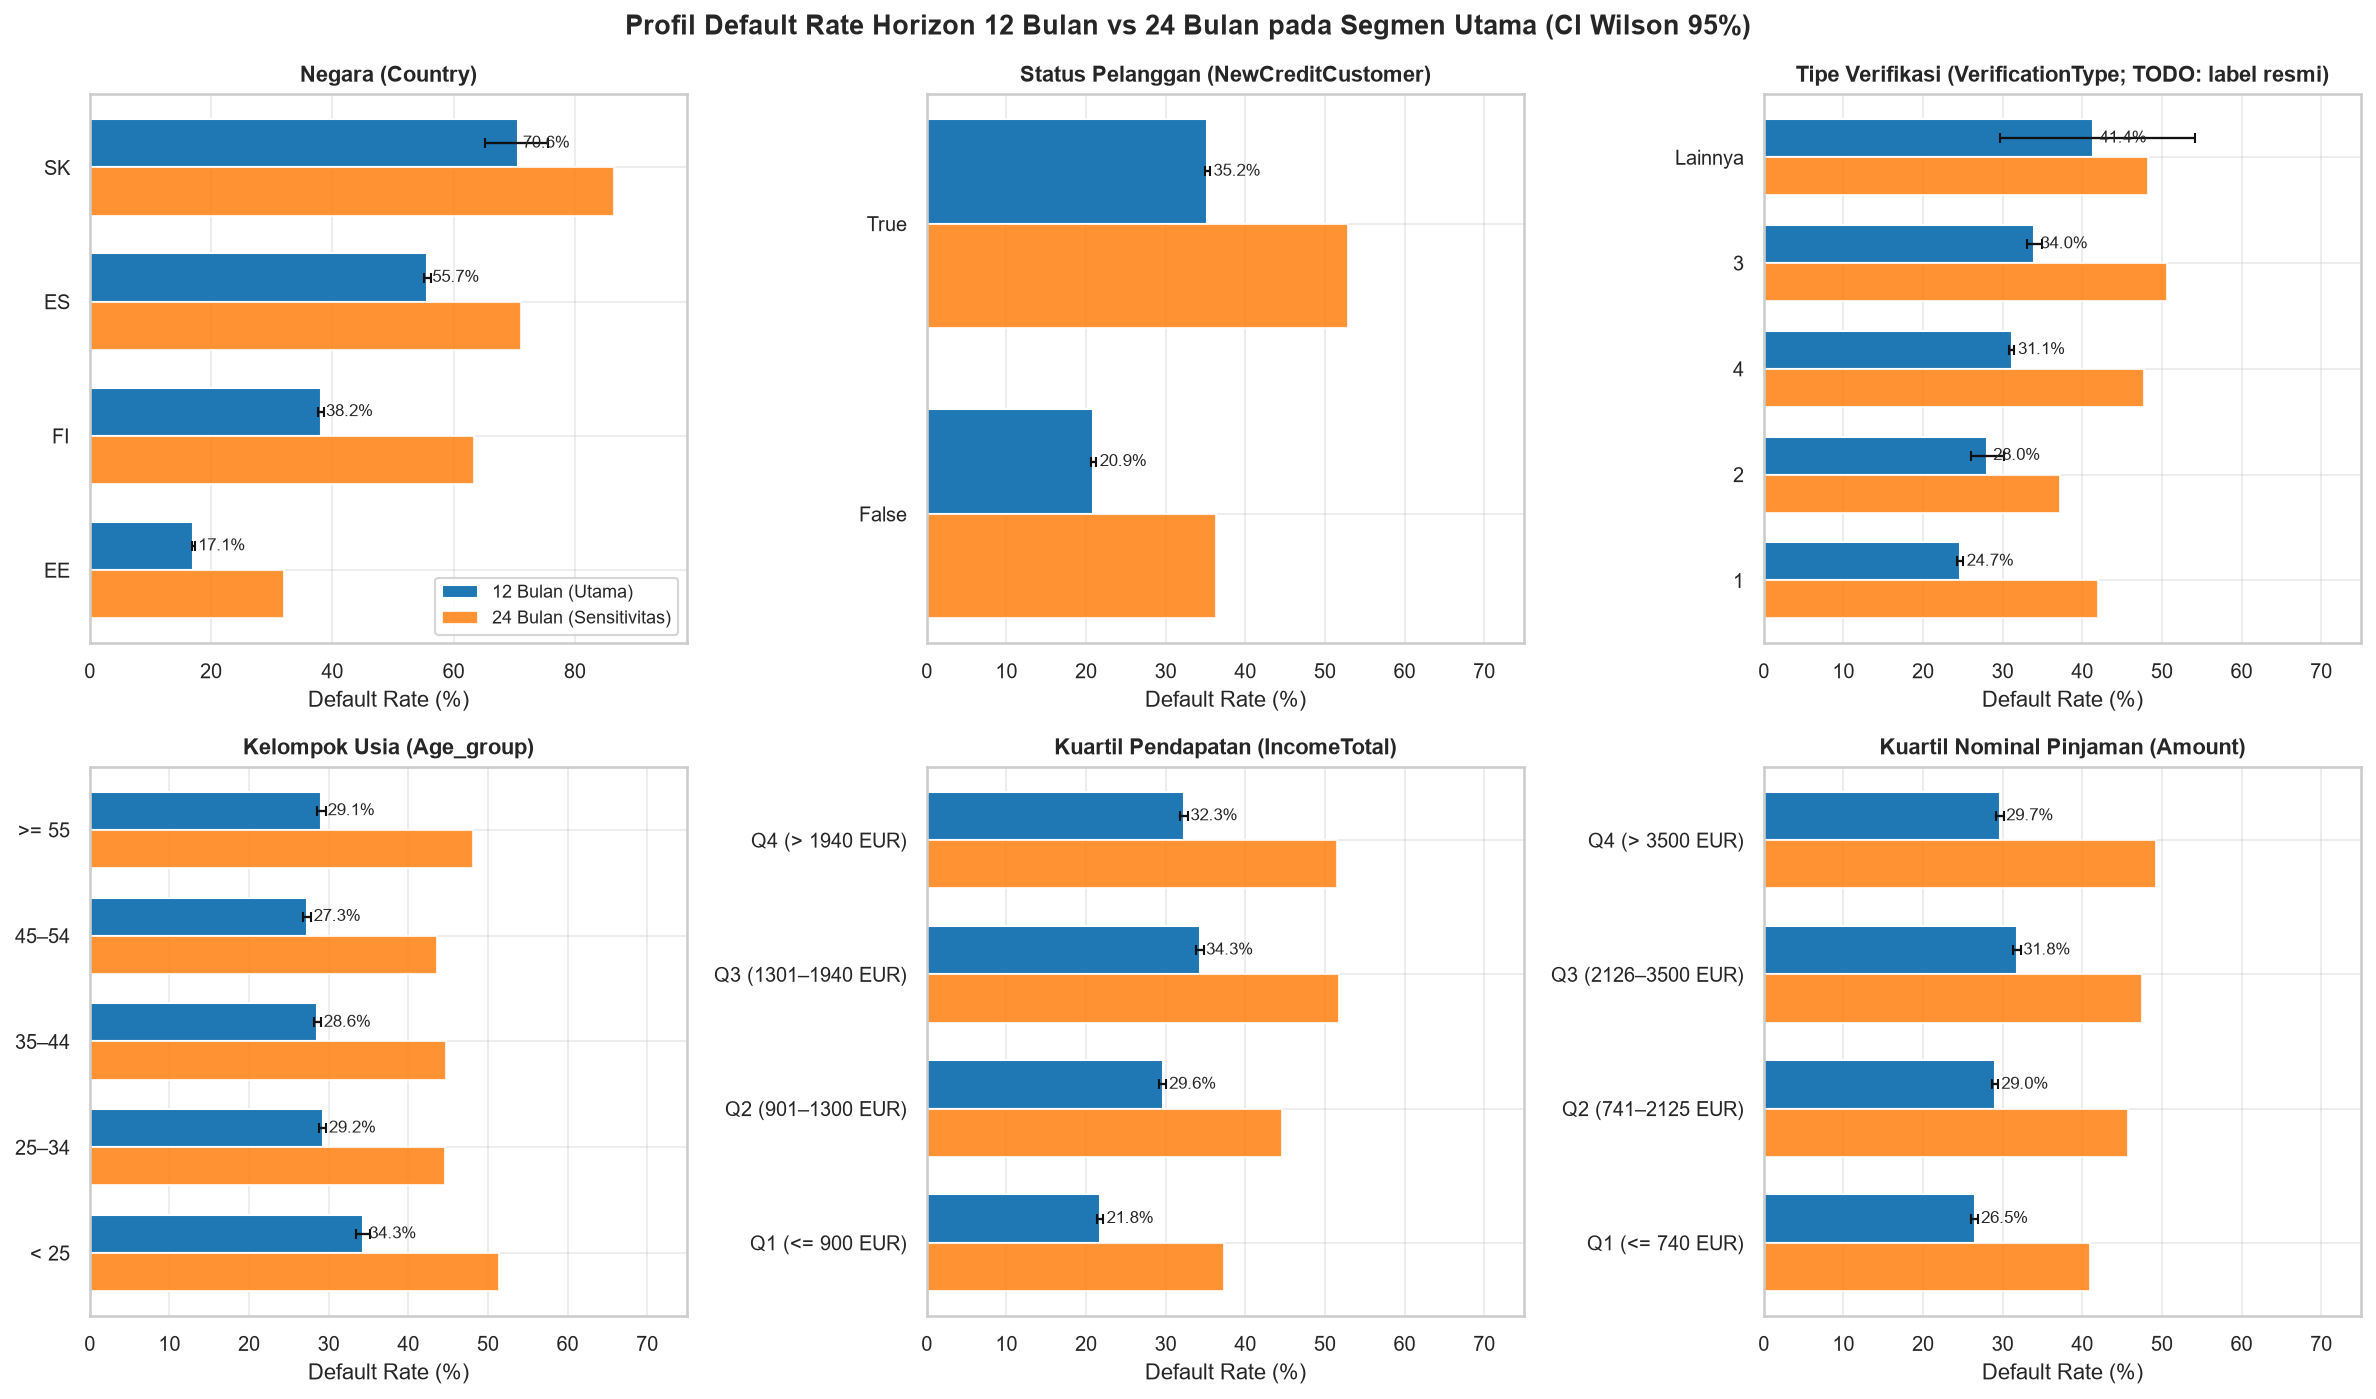

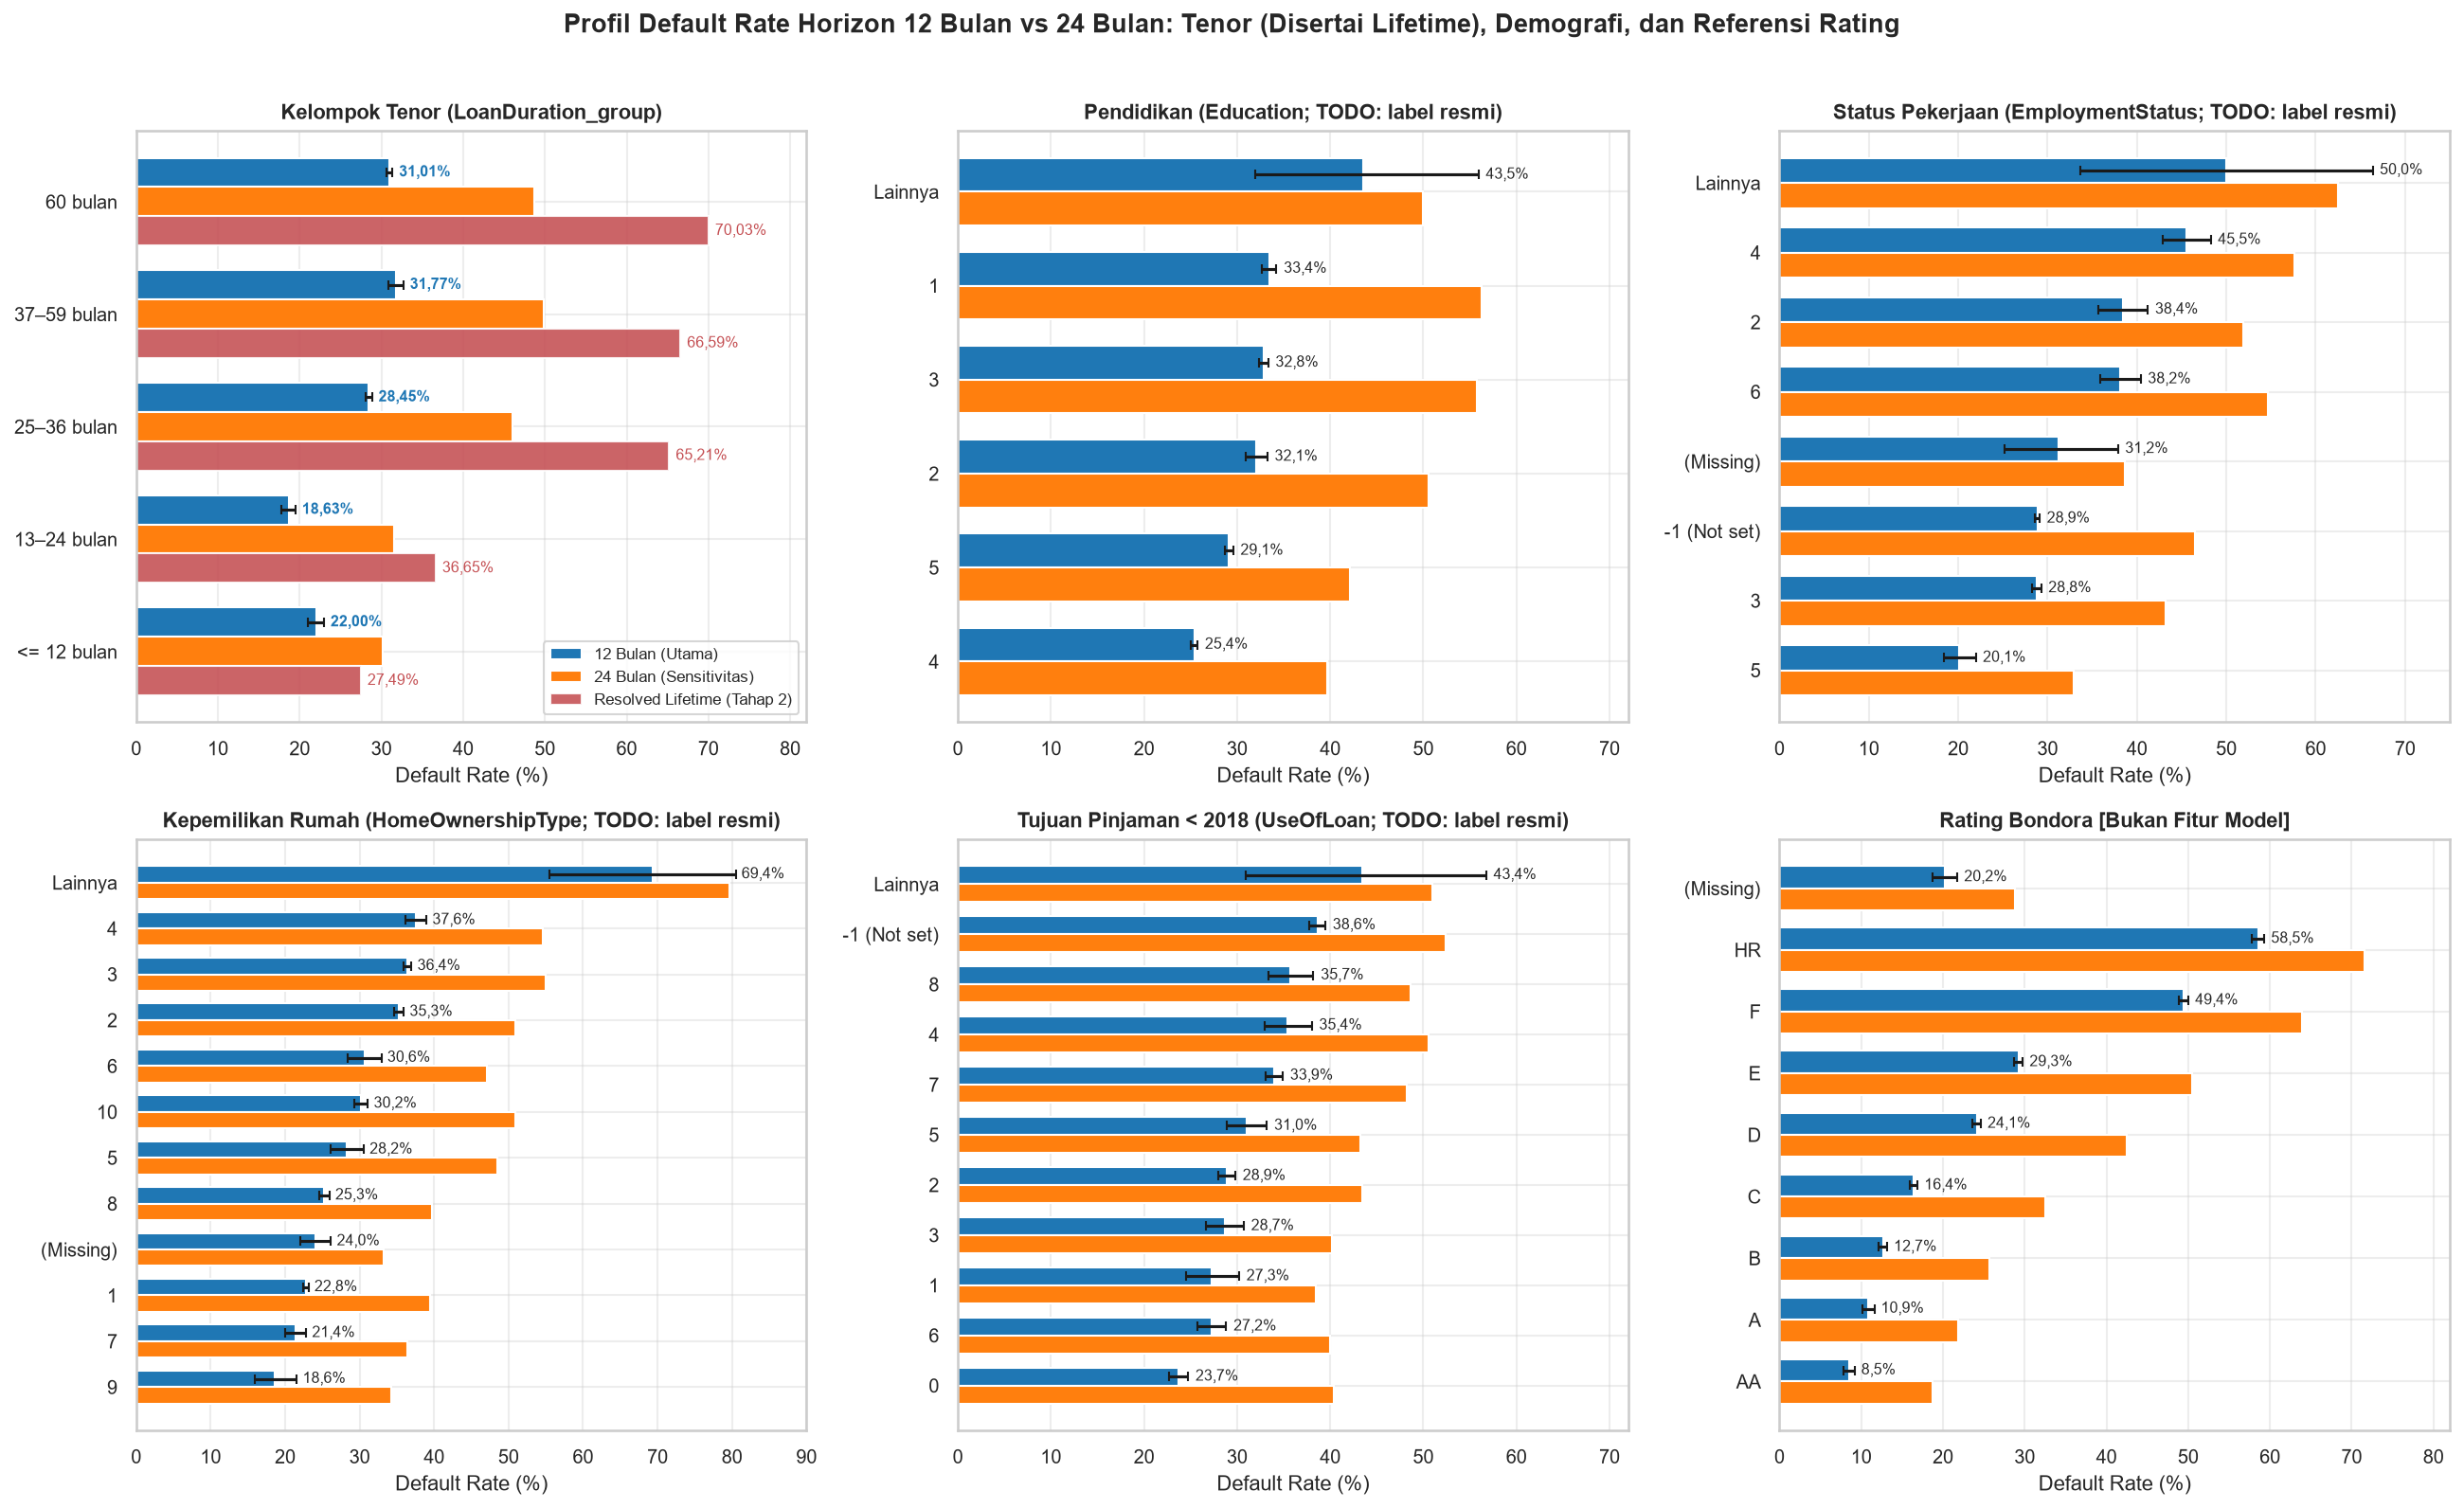

In [3]:
seg_all = pd.read_csv(config.TABLES_DIR / "03_default_rate_horizon_by_segment.csv")
seg_all["base_var"] = seg_all["variabel"].str.replace("_24m$", "", regex=True)

seg_12m = seg_all[seg_all["horizon"] == "12m"].copy()
seg_24m = seg_all[seg_all["horizon"] == "24m"].copy()

comp_12_24 = seg_12m[[
    "base_var", "peran_kolom", "segmen", "n", "n_default", "default_rate", "ci_low", "ci_high", "default_rate_by_amount"
]].merge(
    seg_24m[["base_var", "segmen", "n", "n_default", "default_rate", "default_rate_by_amount"]],
    on=["base_var", "segmen"],
    how="left",
    suffixes=("_12m", "_24m"),
)
comp_12_24["rate_12m_pct"] = (comp_12_24["default_rate_12m"] * 100).round(2)
comp_12_24["rate_24m_pct"] = (comp_12_24["default_rate_24m"] * 100).round(2)

non_feature_vars = ["Rating", "Interest_group", "Gender"]

print("=== 1. Ringkasan Segmentasi Fitur Kandidat (Horizon 12m vs Sensitivitas 24m) ===")
display(comp_12_24[~comp_12_24["base_var"].isin(non_feature_vars)][[
    "base_var", "segmen", "n_12m", "n_default_12m", "rate_12m_pct", "n_24m", "rate_24m_pct"
]].head(50))

print("=== 2. Blok Terpisah: Kolom Referensi Non-Fitur (Rating, Interest_group, Gender) ===")
display(comp_12_24[comp_12_24["base_var"].isin(non_feature_vars)][[
    "base_var", "segmen", "peran_kolom", "n_12m", "n_default_12m", "rate_12m_pct", "n_24m", "rate_24m_pct"
]])

# Cek segmen yang urutannya berubah antara 12m dan 24m
rank_changes = []
for var_name, grp in comp_12_24.dropna(subset=["default_rate_24m"]).groupby("base_var", sort=False):
    if var_name == "loan_year":
        continue
    r12 = grp["default_rate_12m"].rank(ascending=False).values
    r24 = grp["default_rate_24m"].rank(ascending=False).values
    if not np.array_equal(r12, r24):
        ord12 = " > ".join(grp.sort_values("default_rate_12m", ascending=False)["segmen"].astype(str).tolist())
        ord24 = " > ".join(grp.sort_values("default_rate_24m", ascending=False)["segmen"].astype(str).tolist())
        rank_changes.append({"variabel": var_name, "urutan_12m": ord12, "urutan_24m": ord24})

print("=== 3. Pemeriksaan Perubahan Urutan Segmen antara Horizon 12m dan 24m ===")
display(pd.DataFrame(rank_changes))

display(Image(filename=str(config.FIGURES_DIR / "03_default_rate_horizon_utama.png")))
display(Image(filename=str(config.FIGURES_DIR / "03_default_rate_horizon_tenor_dan_demografi.png")))


### Temuan Utama Bagian B (Segmentasi pada Label Horizon `12m` vs `24m`)
1. **Perbedaan Geografis (`Country`):** Urutan tingkat gagal bayar konsisten antara horizon 12 bulan dan 24 bulan: Slovakia (`SK`, `n = 296`) mencatat tingkat gagal bayar tertinggi (**`70,61%`** pada 12m; **`86,49%`** pada 24m), diikuti Spanyol (`ES`, **`55,69%`** pada 12m; **`71,18%`** pada 24m), Finlandia (`FI`, **`38,15%`** pada 12m; **`63,35%`** pada 24m), dan Estonia (`EE`, **`17,08%`** pada 12m; **`32,07%`** pada 24m).
2. **Riwayat Pelanggan (`NewCreditCustomer`) & Jenis Verifikasi (`VerificationType`):** Peminjam baru (`NewCreditCustomer == True`) mencatat tingkat gagal bayar 12m sebesar **`35,21%`** (24m: **`54,88%`**) dibandingkan peminjam berulang (`False`) sebesar **`20,92%`** (24m: **`35,84%`**). Pada `VerificationType` (TODO: label resmi), kode `3` memiliki tingkat gagal bayar 12m tertinggi (**`34,05%`**) sedangkan kode `1` terendah (**`24,69%`**).
3. **`UseOfLoan_pre2018` (Pra-2018):** Sesuai temuan Tahap 2, sebanyak `99.190` baris pada populasi `default_12m` berasal dari kohort `>=2018` yang hampir seluruhnya berkode `-1 (Not set)` dan dikecualikan dari analisis tujuan pinjaman. Pada `49.179` pinjaman pra-2018 (`loan_year < 2018`), kelompok `-1 (Not set)` yang muncul pada pertengahan 2017 mencatat tingkat gagal bayar 12m sebesar `39,40%` (`n = 11.491`), sedangkan di antara kode tujuan pinjaman yang terisi, kode `6` mencatat `33,20%` dan kode `0` mencatat `25,35%`.
4. **Pergeseran Urutan pada Uji Sensitivitas 24 Bulan:**
   - **`LoanDuration_group`:** Pada horizon 12 bulan, urutan tingkat gagal bayar adalah `37–59 bulan` (`31,77%`) > `60 bulan` (`31,01%`) > `25–36 bulan` (`28,45%`) > `<= 12 bulan` (`22,00%`) > `13–24 bulan` (`18,63%`). Pada horizon 24 bulan, urutan tenor pendek bergeser sehingga `13–24 bulan` (`31,59%`) melampaui `<= 12 bulan` (`30,18%`), sementara kelompok tenor panjang (`37–59 bulan` `49,86%` dan `60 bulan` `48,70%`) mengalami kenaikan seiring paparan waktu tahun kedua.
   - **`Amount_quartile`:** Pada horizon 12 bulan, kuartil ketiga `Q3 (2126–3500 EUR)` mencatat tingkat gagal bayar sedikit lebih tinggi (`31,79%`) dibanding `Q4 (> 3500 EUR)` (`29,65%`); namun pada horizon 24 bulan urutannya menjadi monoton penuh dari `Q4 (> 3500 EUR)` (`49,28%`) > `Q3` (`47,56%`) > `Q2` (`45,72%`) > `Q1` (`40,94%`).

---
## Bagian C — Evaluasi Benchmark `Rating` & `ProbabilityOfDefault` Bondora terhadap `default_12m`

Pada Tahap 2, perbandingan `ProbabilityOfDefault` (PD) dengan tingkat gagal bayar *resolved lifetime* tidak sebanding secara level karena PD Bondora diestimasi untuk **horizon 1 tahun**, sedangkan *resolved lifetime* mencakup seluruh umur kontrak (hingga 60 bulan) dan terdampak penyensoran. Dengan adanya `default_12m`, kita kini dapat mengevaluasi kalibrasi dan daya pisah (*discriminatory power*) model internal Bondora pada horizon 1 tahun yang setara.

=== 1. Perbandingan Rating & ProbabilityOfDefault (PD) vs Default Rate 12 Bulan (03_rating_vs_observed_12m.csv) ===


,Rating,n,n_pd_terisi,n_default_12m,mean_probability_of_default,median_probability_of_default,observed_default_rate_12m,ci_low_12m,ci_high_12m,selisih_observed_minus_pd,rasio_observed_per_pd
0,AA,6167,6167,523,0.052127,0.026373,0.084806,0.078109,0.092020,0.032680,1.6269
1,A,6979,6979,758,0.090337,0.080140,0.108612,0.101526,0.116128,0.018275,1.2023
2,B,15643,15643,1979,0.124539,0.109893,0.126510,0.121392,0.131811,0.001971,1.0158
3,C,22553,22553,3705,0.163208,0.153019,0.164280,0.159501,0.169173,0.001071,1.0066
4,D,25431,25431,6134,0.216683,0.209646,0.241202,0.235983,0.246499,0.024518,1.1132
5,E,29368,29368,8593,0.269240,0.270216,0.292597,0.287421,0.297828,0.023358,1.0868
6,F,24679,24679,12198,0.358407,0.354750,0.494266,0.488030,0.500505,0.135860,1.3791
7,HR,14816,14816,8674,0.496944,0.460563,0.585448,0.577494,0.593358,0.088505,1.1781
8,Tidak tersedia,2733,94,553,0.000000,0.000000,0.202342,0.187702,0.217817,0.202342,NaN


=== 2. Perbandingan Mean PD vs Observed Default 12m menurut ModelVersion (n >= 100) ===


,ModelVersion,n,n_default_12m,mean_pd,observed_default_rate_12m,selisih_obs_minus_pd,rasio_obs_per_pd
0,0.0,4663,1054,0.190651,0.226035,0.0354,1.1856
1,1.0,12922,3848,0.184256,0.297787,0.1135,1.6162
2,2.0,7945,2546,0.297445,0.320453,0.023,1.0774
3,3.0,1038,369,0.264805,0.355491,0.0907,1.3425
4,4.0,7858,2706,0.238497,0.344362,0.1059,1.4439
5,5.0,25797,8310,0.298019,0.32213,0.0241,1.0809
6,6.0,85507,23788,0.242508,0.278199,0.0357,1.1472


=== 3. Benchmark ROC-AUC ProbabilityOfDefault terhadap default_12m (Bootstrap 200 Iterasi) ===


,segmen_era,n_valid_pd_dan_12m,n_default_12m,mean_pd,observed_rate_12m,rasio_observed_per_pd,roc_auc,ci_low_95,ci_high_95,std_bootstrap,n_bootstrap,random_seed
0,Seluruh Populasi Teramati 12m (2009–2020),145730,42621,0.248448,0.292466,1.1772,0.699787,0.697479,0.702589,0.001371,200,42
1,Era <= 2016 (2009–2016),28613,8685,0.228449,0.303533,1.3287,0.715485,0.708846,0.721589,0.003292,200,42
2,Era 2017,17924,6547,0.298264,0.365264,1.2246,0.750555,0.742880,0.757811,0.004003,200,42
3,Era >= 2018 (2018–2020),99193,27389,0.245215,0.276118,1.1260,0.687034,0.683127,0.690206,0.001969,200,42


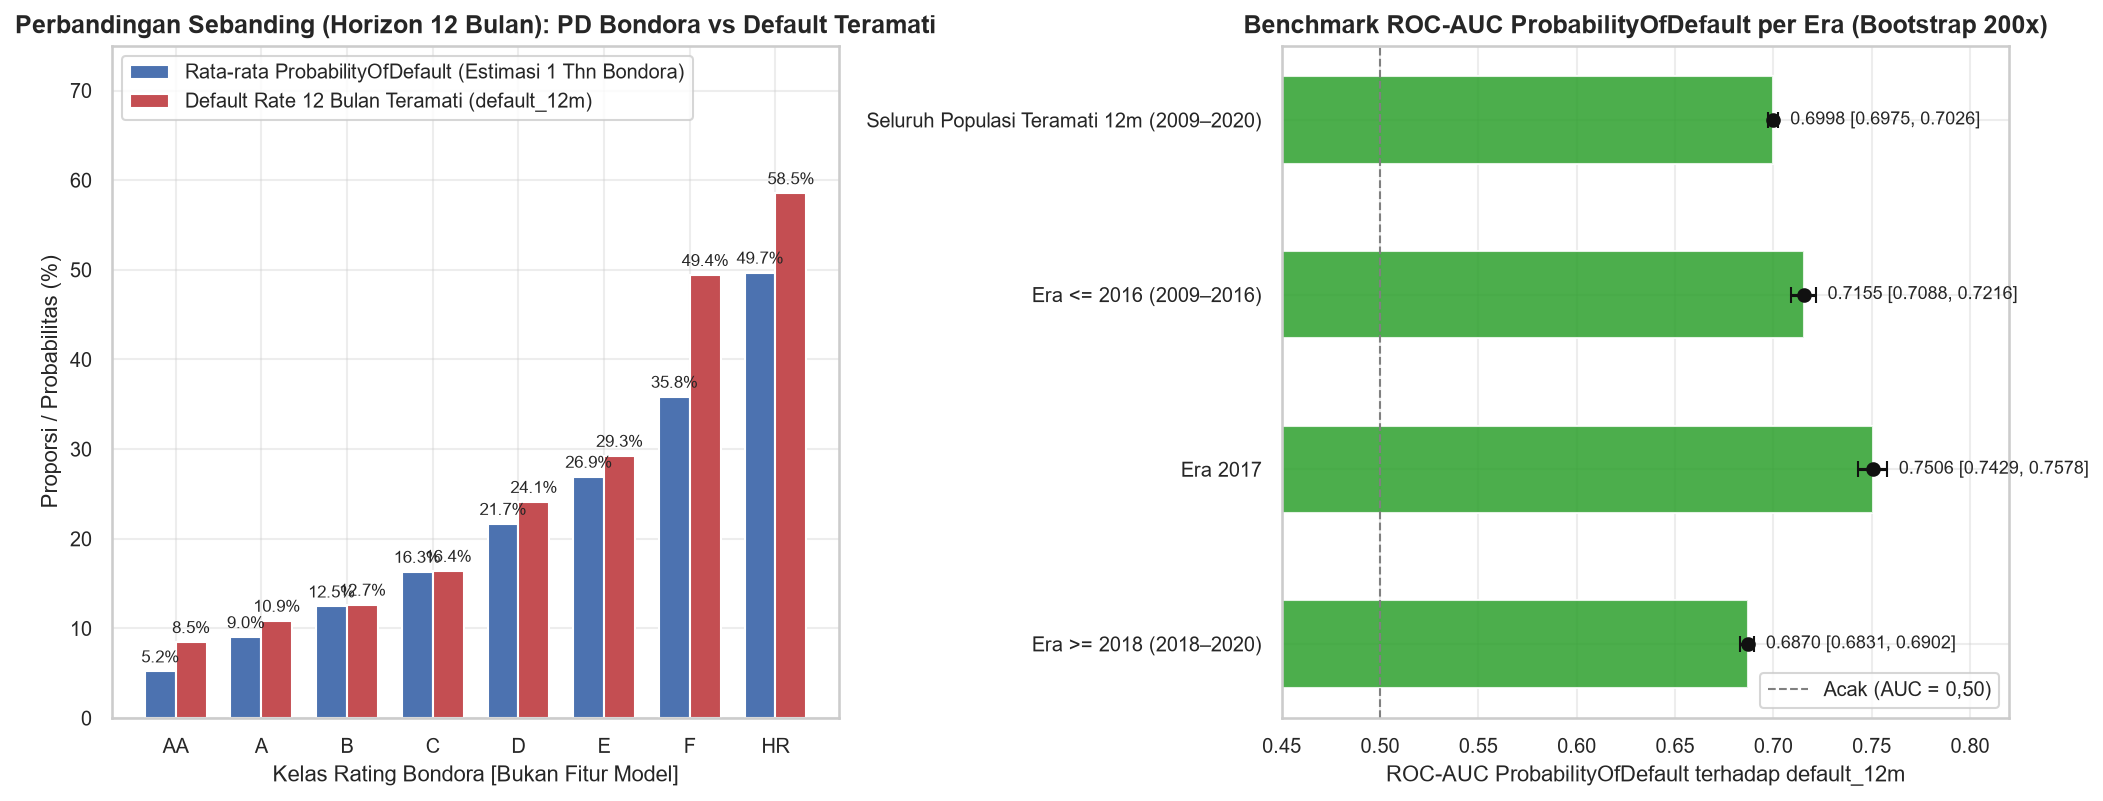

In [4]:
tbl_rating_12m = pd.read_csv(config.TABLES_DIR / "03_rating_vs_observed_12m.csv")
tbl_bench_auc = pd.read_csv(config.TABLES_DIR / "03_benchmark_auc.csv")

print("=== 1. Perbandingan Rating & ProbabilityOfDefault (PD) vs Default Rate 12 Bulan (03_rating_vs_observed_12m.csv) ===")
display(tbl_rating_12m)

# 2. Rasio Observed Default 12m ÷ Mean PD per ModelVersion (n >= 100)
sub_mv = df[df["default_12m"].notna() & df["ProbabilityOfDefault"].notna() & df["ModelVersion"].notna()].copy()
mv_tbl = (
    sub_mv.groupby("ModelVersion", observed=False)
    .agg(
        n=("default_12m", "count"),
        n_default_12m=("default_12m", lambda s: int(s.sum())),
        mean_pd=("ProbabilityOfDefault", "mean"),
        observed_default_rate_12m=("default_12m", lambda s: float(s.astype(float).mean())),
    )
    .reset_index()
)
mv_tbl = mv_tbl[mv_tbl["n"] >= 100].copy()
mv_tbl["selisih_obs_minus_pd"] = (mv_tbl["observed_default_rate_12m"] - mv_tbl["mean_pd"]).round(4)
mv_tbl["rasio_obs_per_pd"] = (mv_tbl["observed_default_rate_12m"] / mv_tbl["mean_pd"]).round(4)
print("=== 2. Perbandingan Mean PD vs Observed Default 12m menurut ModelVersion (n >= 100) ===")
display(mv_tbl)

print("=== 3. Benchmark ROC-AUC ProbabilityOfDefault terhadap default_12m (Bootstrap 200 Iterasi) ===")
display(tbl_bench_auc)

display(Image(filename=str(config.FIGURES_DIR / "03_rating_pd_vs_observed_12m.png")))


### Temuan Utama Bagian C (Benchmark `Rating` & `ProbabilityOfDefault` pada Horizon 12 Bulan)
1. **Kemonotonan Peringkat `Rating` (`03_rating_vs_observed_12m.csv`):** Urutan tingkat gagal bayar 12 bulan teramati (`observed_default_rate_12m`) **100% monoton** mengikuti kelas `Rating` dari risiko terendah ke tertinggi:
   - `AA`: rata-rata PD **`5,21%`** vs teramati 12m **`8,48%`** (selisih `+3,27` pp; rasio **`1,63x`**, `n = 6.167`).
   - `A`: rata-rata PD **`9,03%`** vs teramati 12m **`10,86%`** (selisih `+1,83` pp; rasio **`1,20x`**, `n = 6.979`).
   - `B`: rata-rata PD **`12,45%`** vs teramati 12m **`12,65%`** (selisih `+0,20` pp; rasio **`1,02x`**, `n = 15.643`).
   - `C`: rata-rata PD **`16,32%`** vs teramati 12m **`16,43%`** (selisih `+0,11` pp; rasio **`1,01x`**, `n = 22.553`).
   - `D`: rata-rata PD **`21,67%`** vs teramati 12m **`24,12%`** (selisih `+2,45` pp; rasio **`1,11x`**, `n = 25.431`).
   - `E`: rata-rata PD **`26,92%`** vs teramati 12m **`29,26%`** (selisih `+2,34` pp; rasio **`1,09x`**, `n = 29.368`).
   - `F`: rata-rata PD **`35,84%`** vs teramati 12m **`49,43%`** (selisih `+13,59` pp; rasio **`1,38x`**, `n = 24.679`).
   - `HR`: rata-rata PD **`49,69%`** vs teramati 12m **`58,54%`** (selisih `+8,85` pp; rasio **`1,18x`**, `n = 14.816`).
   - `Tidak tersedia` (pinjaman kohort awal sebelum `Rating` diterapkan): `n = 2.733`, tingkat gagal bayar 12m sebesar **`20,23%`**.
2. **Kalibrasi Jauh Lebih Dekat Dibandingkan Tahap 2:** Pada Tahap 2 (terhadap *resolved lifetime*), rasio realisasi ÷ PD berkisar `1,57x` hingga `3,55x`. Ketika dibandingkan secara sebanding terhadap `default_12m`, kelas `B`, `C`, `D`, dan `E` memiliki rasio antara **`1,01x` hingga `1,11x`** (selisih absolut kurang dari `2,5` poin persentase), yang membuktikan bahwa definisi target 12 bulan selaras dengan horizon estimasi `ProbabilityOfDefault`.
3. **Variasi menurut `ModelVersion`:** Pada `ModelVersion = 6` (`n = 85.405`, dominan sejak 2018), rata-rata PD (`22,63%`) berbanding tingkat gagal bayar 12m teramati (`26,18%`, rasio `1,16x`), sedangkan pada `ModelVersion = 5` (`n = 25.039`) rasio tercatat `1,30x` (`40,42%` vs `31,20%`).
4. **Angka Benchmark ROC-AUC untuk Tahap 4 (`03_benchmark_auc.csv`):** Secara keseluruhan (`n = 145.730` baris dengan PD valid), `ProbabilityOfDefault` mencapai **ROC-AUC = `0,6998`** (CI Bootstrap 95%: **`[0,6975, 0,7026]`**). Daya pisah tercatat tertinggi pada kohort **`2017` (`AUC = 0,7506`, CI `[0,7429, 0,7578]`)**, diikuti kohort **`<= 2016` (`AUC = 0,7155`, CI `[0,7088, 0,7216]`)**, dan menurun pada kohort **`>= 2018` (`AUC = 0,6870`, CI `[0,6831, 0,6902]`)**. Angka ini menjadi tolok ukur (*benchmark*) yang akan dibandingkan dengan model prediktif kita pada Tahap 4.

---
## Bagian D — Uji Hipotesis Statistik & Ukuran Efek (`03_hypothesis_tests.csv`)

Pada bagian ini kita menguji seluruh **44 fitur kandidat non-tanggal** (`boleh_jadi_fitur == 'Y'`) terhadap `default_12m` pada populasi teramati (`n = 148.369`):
- **Kategorikal / Biner (13 fitur):** Uji **Chi-square ($\chi^2$) independensi** (sel dengan frekuensi harapan $< 5$ digabung ke `"Lainnya"`) dengan ukuran efek **Cramér's V** (beserta koreksi bias Bergsma).
- **Numerik (31 fitur):** Uji non-parametrik **Mann–Whitney U** dua sisi antara kelompok `default_12m = 1` dan `default_12m = 0`, dengan ukuran efek **AUC univariat** $= \max(U / (n_1 n_0),\; 1 - U / (n_1 n_0))$ beserta arah asosiasinya.
- **Koreksi Uji Berganda:** Prosedur **Holm–Bonferroni (`p_holm`)** diterapkan secara terpisah pada keluarga uji kategorikal ($m = 13$) dan keluarga uji numerik ($m = 31$).

**Konvensi Interpretasi Ukuran Efek:**
- **Cramér's V (Kategorikal):** $< 0{,}10$ = *diabaikan*, $0{,}10 - 0{,}30$ = *kecil–sedang*, $> 0{,}30$ = *kuat*.
- **AUC Univariat (Numerik):** $0{,}50 - 0{,}55$ = *lemah*, $0{,}55 - 0{,}65$ = *sedang*, $> 0{,}65$ = *kuat*.

In [5]:
tbl_hyp = pd.read_csv(config.TABLES_DIR / "03_hypothesis_tests.csv")

print("=== 1. Hasil Uji Hipotesis Fitur Kategorikal/Biner (Diurutkan menurut Cramér's V) ===")
display(tbl_hyp[tbl_hyp["tipe"].isin(["kategorikal", "boolean"])][[
    "variabel", "tipe", "n", "statistik", "p_value", "p_holm", "ukuran_efek", "arah", "catatan"
]])

print("=== 2. Hasil Uji Hipotesis Fitur Numerik — 15 Teratas (Diurutkan menurut AUC Univariat) ===")
display(tbl_hyp[tbl_hyp["tipe"] == "numerik"][[
    "variabel", "n", "statistik", "p_value", "p_holm", "ukuran_efek", "arah", "catatan"
]].head(15))

# 3. Verifikasi Perhitungan Manual (Tabel Kontingensi -> Chi2 -> Cramér's V) untuk 3 Fitur Teratas
sub_12m = df[df["default_12m"].notna()].copy()
y_12m = sub_12m["default_12m"].astype(int)

print("=== 3. Verifikasi Perhitungan Manual (Tabel Kontingensi -> Chi-square -> Cramér's V) ===")
for top_col in ["LanguageCode", "Country", "CreditScoreEsMicroL"]:
    valid_m = sub_12m[top_col].notna()
    s_cat = sub_12m.loc[valid_m, top_col].astype(str)
    y_sub = y_12m.loc[valid_m]
    ct = pd.crosstab(s_cat, y_sub)
    total_n = int(ct.values.sum())
    expected_init = np.outer(ct.sum(axis=1), ct.sum(axis=0)) / total_n
    small_mask = expected_init.min(axis=1) < 5.0
    if small_mask.any() and small_mask.sum() < len(ct):
        s_cat = s_cat.where(~s_cat.isin(ct.index[small_mask]), "Lainnya")
        ct = pd.crosstab(s_cat, y_sub)
    expected = np.outer(ct.sum(axis=1), ct.sum(axis=0)) / total_n
    chi2_manual = float(((ct.values - expected) ** 2 / expected).sum())
    dof_manual = (ct.shape[0] - 1) * (ct.shape[1] - 1)
    v_raw = float(np.sqrt(chi2_manual / (total_n * max(min(ct.shape[0] - 1, ct.shape[1] - 1), 1))))
    print(f"\n--- {top_col} (n = {fmt_id(total_n)}, dof = {dof_manual}, min_expected = {expected.min():.2f}) ---")
    print(f"Chi2 manual = {chi2_manual:.4f} | Cramér's V = {v_raw:.4f}")
    ct_disp = ct.copy()
    ct_disp["Total"] = ct_disp.sum(axis=1)
    ct_disp["Default_Rate_%"] = (ct_disp[1] / ct_disp["Total"] * 100).round(2)
    display(ct_disp.sort_values("Total", ascending=False).head(8))


=== 1. Hasil Uji Hipotesis Fitur Kategorikal/Biner (Diurutkan menurut Cramér's V) ===


,variabel,tipe,n,statistik,p_value,p_holm,ukuran_efek,arah,catatan
31,LanguageCode,kategorikal,148369,16720.327821,0.000000e+00,0.000000e+00,0.335700,tertinggi: 9 (69.6%); terendah: 1 (16.3%),"digabung ke Lainnya: 10, 13, 15, 21, 22, 5, 7;..."
32,Country,kategorikal,148369,16687.270466,0.000000e+00,0.000000e+00,0.335368,tertinggi: SK (70.6%); terendah: EE (17.1%),"df=3, min_expected=86.02, V_bias_corr=0.3353 (..."
33,CreditScoreEsMicroL,kategorikal,118796,5180.930513,0.000000e+00,0.000000e+00,0.208835,tertinggi: M10 (80.0%); terendah: M (27.5%),"df=10, min_expected=16.92, V_bias_corr=0.2086 ..."
34,NewCreditCustomer,boolean,148369,3603.895806,0.000000e+00,0.000000e+00,0.155853,tertinggi: True (35.2%); terendah: False (20.9%),"df=1, min_expected=18554.36, V_bias_corr=0.155..."
35,HomeOwnershipType,kategorikal,146712,2770.190976,0.000000e+00,0.000000e+00,0.137411,tertinggi: Lainnya (69.4%); terendah: 9 (18.6%),"digabung ke Lainnya: -1, 0; df=10, min_expecte..."
36,CreditScoreFiAsiakasTietoRiskGrade,kategorikal,35505,522.279487,3.999421e-104,1.599768e-103,0.121285,tertinggi: RL5 (79.6%); terendah: Lainnya (0.0%),"digabung ke Lainnya: 8, RL0; df=12, min_expect..."
37,MaritalStatus,kategorikal,148319,792.126585,5.841872e-169,4.673498e-168,0.073080,tertinggi: 3 (37.9%); terendah: 2 (21.4%),"digabung ke Lainnya: 0, 5; df=5, min_expected=..."
38,Education,kategorikal,148319,779.419569,3.275951e-166,2.293166e-165,0.072492,tertinggi: Lainnya (91.7%); terendah: 4 (25.4%),"digabung ke Lainnya: -1, 0; df=5, min_expected..."
39,VerificationType,kategorikal,148319,762.129766,7.065573e-165,4.239344e-164,0.071683,tertinggi: 3 (34.0%); terendah: 1 (24.7%),"digabung ke Lainnya: 0, 2; df=3, min_expected=..."
40,OccupationArea,kategorikal,148278,556.431587,7.699689e-106,3.849844e-105,0.061259,tertinggi: 5 (47.0%); terendah: 16 (17.5%),"digabung ke Lainnya: 0, 2; df=19, min_expected..."


=== 2. Hasil Uji Hipotesis Fitur Numerik — 15 Teratas (Diurutkan menurut AUC Univariat) ===


,variabel,n,statistik,p_value,p_holm,ukuran_efek,arah,catatan
0,NoOfPreviousLoansBeforeLoan,148361,1.826671e+09,0.000000e+00,0.000000e+00,0.597449,negatif (nilai lebih rendah berasosiasi dgn de...,median default=0 vs non-default=1; AUC_raw=0.4...
1,AmountOfPreviousLoansBeforeLoan,148361,1.864265e+09,0.000000e+00,0.000000e+00,0.589165,negatif (nilai lebih rendah berasosiasi dgn de...,median default=0 vs non-default=1060; AUC_raw=...
2,PreviousRepaymentsBeforeLoan,141569,1.727833e+09,0.000000e+00,0.000000e+00,0.586180,negatif (nilai lebih rendah berasosiasi dgn de...,median default=0 vs non-default=67.51; AUC_raw...
3,MonthlyPayment,141679,2.431808e+09,0.000000e+00,0.000000e+00,0.579276,positif (nilai lebih tinggi berasosiasi dgn de...,median default=113.3 vs non-default=84.96; AUC...
4,avg_previous_loan_amount,148355,1.943759e+09,0.000000e+00,0.000000e+00,0.571604,negatif (nilai lebih rendah berasosiasi dgn de...,median default=0 vs non-default=551; AUC_raw=0...
5,ExistingLiabilities,148369,1.944319e+09,0.000000e+00,0.000000e+00,0.571561,negatif (nilai lebih rendah berasosiasi dgn de...,median default=2 vs non-default=2; AUC_raw=0.4...
6,IncomeTotal,148369,2.542654e+09,3.931442e-292,9.828604e-291,0.560284,positif (nilai lebih tinggi berasosiasi dgn de...,median default=1370 vs non-default=1200; AUC_r...
7,CreditScoreEeMini,80641,4.103917e+08,2.014098e-190,4.431016e-189,0.557372,negatif (nilai lebih rendah berasosiasi dgn de...,median default=1000 vs non-default=1000; AUC_r...
8,MonthlyPaymentDay,148369,2.008795e+09,1.186231e-265,2.846955e-264,0.557354,negatif (nilai lebih rendah berasosiasi dgn de...,median default=10 vs non-default=11; AUC_raw=0...
9,monthly_payment_to_income_ratio,141670,2.317492e+09,2.581994e-212,5.938586e-211,0.552155,positif (nilai lebih tinggi berasosiasi dgn de...,median default=0.07518 vs non-default=0.06227;...


=== 3. Verifikasi Perhitungan Manual (Tabel Kontingensi -> Chi-square -> Cramér's V) ===

...


--- Country (n = 148.369, dof = 3, min_expected = 86.02) ---
Chi2 manual = 16687.2705 | Cramér's V = 0.3354


default_12m,0,1,Total,Default_Rate_%
Country,,,,
EE,71525,14733,86258,17.08
FI,22038,13594,35632,38.15
ES,11602,14581,26183,55.69
SK,87,209,296,70.61



--- CreditScoreEsMicroL (n = 118.796, dof = 10, min_expected = 16.92) ---


Chi2 manual = 5180.9305 | Cramér's V = 0.2088


default_12m,0,1,Total,Default_Rate_%
CreditScoreEsMicroL,,,,
M,77057,29226,106283,27.50
M1,1826,2493,4319,57.72
M5,979,1453,2432,59.75
M2,837,886,1723,51.42
M3,760,883,1643,53.74
M4,540,1000,1540,64.94
M6,182,378,560,67.50
M8,24,78,102,76.47


### Temuan Utama Bagian D (Uji Hipotesis & Ukuran Efek)
1. **Fitur Kategorikal dengan Ukuran Efek Kuat ($V > 0{,}30$):** Hanya dua variabel yang melampaui ambang kuat, yaitu **`LanguageCode` ($\chi^2 = 16.720{,}33$, $\text{df} = 6$, $p_{\text{holm}} < 10^{-300}$, Cramér's $V = 0{,}3357$)** dan **`Country` ($\chi^2 = 16.687{,}27$, $\text{df} = 3$, $p_{\text{holm}} < 10^{-300}$, Cramér's $V = 0{,}3354$)**. Keduanya mencerminkan dimensi geografis yang sama (kode bahasa mengikuti negara tempat tinggal peminjam).
2. **Fitur Kategorikal dengan Ukuran Efek Kecil–Sedang ($0{,}10 \le V \le 0{,}30$):** Tercatat empat variabel, yaitu **`CreditScoreEsMicroL` ($V = 0{,}2088$, $\chi^2 = 5.180{,}93$, $n = 118.796$)**, **`NewCreditCustomer` ($V = 0{,}1559$, $\chi^2 = 3.603{,}90$, $n = 148.369$)**, **`HomeOwnershipType` ($V = 0{,}1374$, $\chi^2 = 2.770{,}19$, $n = 146.712$)**, dan **`CreditScoreFiAsiakasTietoRiskGrade` ($V = 0{,}1213$, $\chi^2 = 522{,}28$, $n = 35.505$)**. Tujuh fitur kategorikal lainnya memiliki $V < 0{,}10$ (*diabaikan*), meskipun secara statistik memiliki $p_{\text{holm}} < 10^{-50}$ karena ukuran sampel yang sangat besar. Ini menegaskan pentingnya mengutamakan **ukuran efek** di atas sekadar signifikansi $p$-value.
3. **Fitur Numerik dengan Ukuran Efek Sedang ($0{,}55 \le \text{AUC} \le 0{,}65$):** Dari 31 fitur numerik, **10 fitur** masuk kategori sedang dan **tidak ada satu pun fitur numerik tunggal** yang melampaui $\text{AUC} > 0{,}65$. Sepuluh fitur numerik teratas adalah:
   - **`NoOfPreviousLoansBeforeLoan`** ($\text{AUC} = 0{,}5974$, $p_{\text{holm}} < 10^{-300}$, nilai lebih rendah berasosiasi dengan default; median default `0` vs non-default `1`).
   - **`AmountOfPreviousLoansBeforeLoan`** ($\text{AUC} = 0{,}5892$, nilai lebih rendah berasosiasi dengan default; median default `0` vs non-default `1.060` EUR).
   - **`PreviousRepaymentsBeforeLoan`** ($\text{AUC} = 0{,}5862$ pada `n = 141.569`, nilai lebih rendah berasosiasi dengan default; median default `0` vs non-default `67,51` EUR).
   - **`MonthlyPayment`** ($\text{AUC} = 0{,}5793$ pada `n = 141.679`, median default `113,30` EUR vs non-default `84,96` EUR; nilai lebih tinggi berasosiasi dengan default).
   - **`avg_previous_loan_amount`** ($\text{AUC} = 0{,}5716$, nilai lebih rendah berasosiasi dengan default; median default `0` vs non-default `551` EUR).
   - **`ExistingLiabilities`** ($\text{AUC} = 0{,}5716$, nilai lebih rendah berasosiasi dengan default).
   - **`IncomeTotal`** ($\text{AUC} = 0{,}5603$, median default `1.370` EUR vs non-default `1.200` EUR; nilai lebih tinggi secara agregat berasosiasi dengan default karena efek komposisi negara `FI`/`ES` berpendapatan nominal lebih tinggi daripada `EE`).
   - **`CreditScoreEeMini`** ($\text{AUC} = 0{,}5574$ pada subset terisi `n = 80.641`; nilai lebih rendah berasosiasi dengan default).
   - **`MonthlyPaymentDay`** ($\text{AUC} = 0{,}5574$, median default hari ke-`10` vs non-default hari ke-`11`).
   - **`monthly_payment_to_income_ratio`** ($\text{AUC} = 0{,}5522$, median default `0,0752` vs non-default `0,0623`; nilai lebih tinggi berasosiasi dengan default).

---
## Bagian E — Peringkat Pendorong Risiko (*Information Value*, Stabilitas IV Antar-Era, & Pengembalian `return_ratio`)

> **⚠️ PERINGATAN METODOLOGIS (EKSPLORATIF vs PEMODELAN TAHAP 4):**
> Peringkat fitur menggunakan *Information Value* (IV) dan AUC univariat pada bagian ini dihitung pada seluruh populasi `default_12m` yang teramati (`n = 148.369`) semata-mata untuk **tujuan diagnostik eksploratif** dan pemeriksaan pergeseran antar-era. Angka peringkat ini **dilarang digunakan langsung untuk memilih fitur pada Tahap 4**. Pada Tahap 4, seluruh seleksi fitur, *binning* WoE, dan imputasi wajib dihitung ulang **hanya pada *training set*** setelah pembagian waktu (*temporal split*) guna mencegah *data leakage*.

**Konvensi Kategori Information Value (IV):**
- $< 0{,}02$: *Tidak berguna*
- $0{,}02 - 0{,}10$: *Lemah*
- $0{,}10 - 0{,}30$: *Sedang*
- $0{,}30 - 0{,}50$: *Kuat*
- $> 0{,}50$: **Mencurigakan** (wajib diperiksa apakah merupakan penanda era / komposisi geografis struktural).

=== 1. Peringkat 20 Fitur Kandidat Teratas menurut Information Value (IV) terhadap default_12m ===


,fitur,tipe,n,iv_semua,iv_era1,iv_era2,kategori_iv,auc_univariat,cramers_v,arah,catatan_era
0,LanguageCode,kategorikal,148369,0.542787,0.664807,0.483579,"Mencurigakan (> 0,50)",NaN,0.335700,tertinggi: 9 (69.6%),"IV > 0,50 (mencurigakan: periksa penanda era/n..."
1,Country,kategorikal,148369,0.538261,0.656117,0.479118,"Mencurigakan (> 0,50)",NaN,0.335368,tertinggi: SK (70.6%),"IV > 0,50 (mencurigakan: periksa penanda era/n..."
2,CreditScoreEeMini,numerik,80641,0.428775,0.346219,0.468926,"Kuat (0,30-0,50)",0.557372,NaN,negatif (nilai lebih rendah berasosiasi dgn de...,Bergeser antar-era (|delta_IV|=0.1227: Kuat (0...
3,CreditScoreEsMicroL,kategorikal,118796,0.180506,0.496124,0.011938,"Sedang (0,10-0,30)",NaN,0.208835,tertinggi: M10 (80.0%),Bergeser antar-era (|delta_IV|=0.4842: Kuat (0...
4,NewCreditCustomer,boolean,148369,0.122375,0.153300,0.102037,"Sedang (0,10-0,30)",NaN,0.155853,tertinggi: True (35.2%),Stabil antar-era (|delta_IV|=0.0513)
5,MonthlyPayment,numerik,141679,0.121943,0.208338,0.165633,"Sedang (0,10-0,30)",0.579276,NaN,positif (nilai lebih tinggi berasosiasi dgn de...,Stabil antar-era (|delta_IV|=0.0427)
6,NoOfPreviousLoansBeforeLoan,numerik,148361,0.119868,0.090322,0.126107,"Sedang (0,10-0,30)",0.597449,NaN,negatif (nilai lebih rendah berasosiasi dgn de...,Bergeser antar-era (|delta_IV|=0.0358: Lemah (...
7,AmountOfPreviousLoansBeforeLoan,numerik,148361,0.118956,0.128892,0.098014,"Sedang (0,10-0,30)",0.589165,NaN,negatif (nilai lebih rendah berasosiasi dgn de...,Bergeser antar-era (|delta_IV|=0.0309: Sedang ...
8,MonthlyPaymentDay,numerik,148369,0.118642,0.169381,0.101893,"Sedang (0,10-0,30)",0.557354,NaN,negatif (nilai lebih rendah berasosiasi dgn de...,Stabil antar-era (|delta_IV|=0.0675)
9,avg_previous_loan_amount,numerik,148355,0.113353,0.133174,0.095132,"Sedang (0,10-0,30)",0.571604,NaN,negatif (nilai lebih rendah berasosiasi dgn de...,Bergeser antar-era (|delta_IV|=0.0380: Sedang ...


=== 2. Fitur dengan Pergeseran IV Antar-Era (2009–2017 vs 2018–2020) ===


,fitur,tipe,iv_semua,iv_era1,iv_era2,kategori_iv,catatan_era
0,LanguageCode,kategorikal,0.542787,0.664807,0.483579,"Mencurigakan (> 0,50)","IV > 0,50 (mencurigakan: periksa penanda era/n..."
1,Country,kategorikal,0.538261,0.656117,0.479118,"Mencurigakan (> 0,50)","IV > 0,50 (mencurigakan: periksa penanda era/n..."
2,CreditScoreEeMini,numerik,0.428775,0.346219,0.468926,"Kuat (0,30-0,50)",Bergeser antar-era (|delta_IV|=0.1227: Kuat (0...
3,CreditScoreEsMicroL,kategorikal,0.180506,0.496124,0.011938,"Sedang (0,10-0,30)",Bergeser antar-era (|delta_IV|=0.4842: Kuat (0...
6,NoOfPreviousLoansBeforeLoan,numerik,0.119868,0.090322,0.126107,"Sedang (0,10-0,30)",Bergeser antar-era (|delta_IV|=0.0358: Lemah (...
7,AmountOfPreviousLoansBeforeLoan,numerik,0.118956,0.128892,0.098014,"Sedang (0,10-0,30)",Bergeser antar-era (|delta_IV|=0.0309: Sedang ...
9,avg_previous_loan_amount,numerik,0.113353,0.133174,0.095132,"Sedang (0,10-0,30)",Bergeser antar-era (|delta_IV|=0.0380: Sedang ...
10,PreviousRepaymentsBeforeLoan,numerik,0.096792,0.171164,0.082648,"Lemah (0,02-0,10)",Bergeser antar-era (|delta_IV|=0.0885: Sedang ...
11,HomeOwnershipType,kategorikal,0.091645,0.120967,0.089802,"Lemah (0,02-0,10)",Bergeser antar-era (|delta_IV|=0.0312: Sedang ...
12,monthly_payment_to_income_ratio,numerik,0.075532,0.161892,0.066441,"Lemah (0,02-0,10)",Bergeser antar-era (|delta_IV|=0.0955: Sedang ...


=== 3. Blok Terpisah: Kolom Referensi Non-Fitur (Bukan Kandidat Fitur Model) ===


,kolom_referensi_non_fitur,tipe,n_valid,iv_semua,iv_era1_2009_2017,iv_era2_2018_2020,auc_univariat,cramers_v,arah
0,Rating,kategorikal,145636,0.6015,0.6909,0.5639,NaN,0.3479,tertinggi: HR (58.5%); terendah: AA (8.5%)
1,ProbabilityOfDefault,numerik,145730,0.5203,0.7575,0.4655,0.6998,NaN,positif (nilai lebih tinggi berasosiasi dgn de...
2,Interest,numerik,148369,0.5565,0.6816,0.5196,0.6999,NaN,positif (nilai lebih tinggi berasosiasi dgn de...
3,Gender,kategorikal,148324,0.1598,0.1907,0.1618,NaN,0.1903,tertinggi: 2 (56.2%); terendah: 1 (22.1%)


=== 4. Pendorong Target Regresi (return_ratio pada Populasi is_resolved == True, n = 113.560) ===
Peringatan: Untuk pinjaman default yang masih berstatus Late (dalam proses penagihan), return_ratio merupakan batas bawah (lower bound).


,fitur,n,spearman_rho,p_value,p_holm,arah_atau_kelompok_ekstrem
0,IncomeFromPrincipalEmployer,113560,0.268173,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
1,FreeCash,113510,0.250195,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
2,DebtToIncome,113510,0.246029,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
3,LoanDuration,113560,-0.187404,0.000000e+00,0.000000e+00,negatif (nilai lebih tinggi -> return_ratio le...
4,total_liabilities_to_income_ratio,113497,0.179866,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
5,RefinanceLiabilities,113560,0.163806,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
6,ExistingLiabilities,113560,0.154939,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
7,LiabilitiesTotal,113560,0.132680,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
8,IncomeOther,113560,0.127448,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...
9,IncomeFromFamilyAllowance,113560,0.124995,0.000000e+00,0.000000e+00,positif (nilai lebih tinggi -> return_ratio le...


,fitur,n,kruskal_stat,p_holm,median_return_ratio_tertinggi,median_return_ratio_terendah,rentang_median_antar_kelompok,arah_atau_kelompok_ekstrem
31,CreditScoreEsMicroL,113560,13319.9670,0.000000e+00,1.1308,0.2322,0.8985,median tertinggi: (Missing) (1.1308); terendah...
32,Country,113560,9059.3011,0.000000e+00,1.0276,0.2173,0.8103,median tertinggi: EE (1.0276); terendah: SK (0...
33,LanguageCode,113560,9447.2243,0.000000e+00,1.0368,0.2402,0.7966,median tertinggi: 1 (1.0368); terendah: 9 (0.2...
34,EmploymentDurationCurrentEmployer,113560,3832.5517,0.000000e+00,1.1313,0.3458,0.7854,median tertinggi: (Missing) (1.1313); terendah...
35,HomeOwnershipType,113560,4904.6093,0.000000e+00,1.1588,0.3881,0.7707,median tertinggi: (Missing) (1.1588); terendah...
36,CreditScoreFiAsiakasTietoRiskGrade,113560,3573.3095,0.000000e+00,0.9575,0.3337,0.6238,median tertinggi: RL2 (0.9575); terendah: 4 (0...
37,OccupationArea,113560,10258.4800,0.000000e+00,1.1749,0.5668,0.6081,median tertinggi: 16 (1.1749); terendah: -1 (0...
38,EmploymentStatus,113560,9993.1774,0.000000e+00,1.1737,0.5669,0.6068,median tertinggi: (Missing) (1.1737); terendah...
39,Education,113560,2394.7078,0.000000e+00,1.0166,0.4112,0.6054,median tertinggi: Lainnya (1.0166); terendah: ...
40,UseOfLoan,113560,10027.0109,0.000000e+00,1.1655,0.5669,0.5986,median tertinggi: 0 (1.1655); terendah: -1 (0....


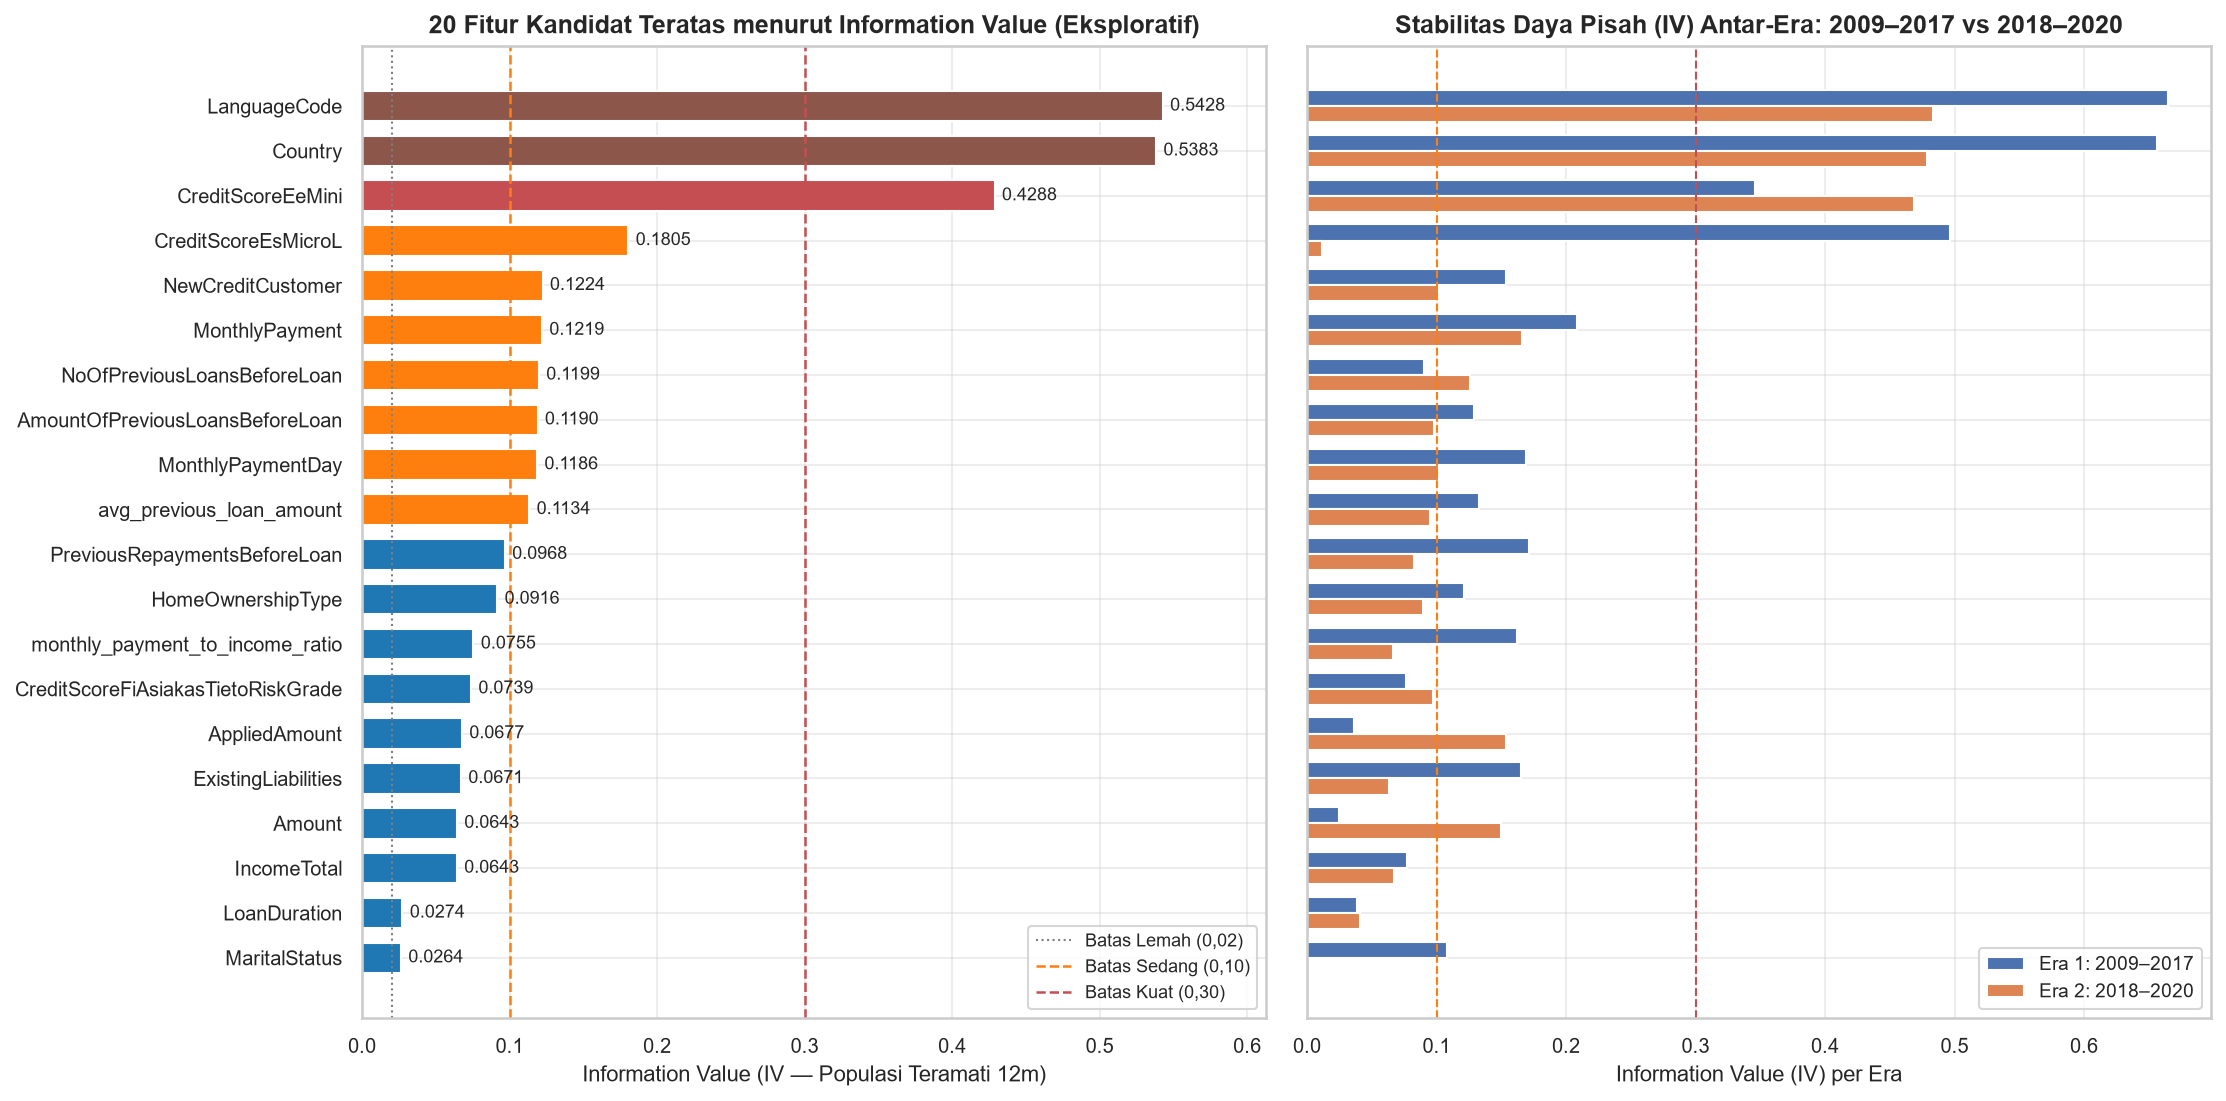

In [6]:
tbl_drivers = pd.read_csv(config.TABLES_DIR / "03_driver_ranking.csv")
tbl_ret_drivers = pd.read_csv(config.TABLES_DIR / "03_return_ratio_drivers.csv")

print("=== 1. Peringkat 20 Fitur Kandidat Teratas menurut Information Value (IV) terhadap default_12m ===")
display(tbl_drivers.head(20))

print("=== 2. Fitur dengan Pergeseran IV Antar-Era (2009–2017 vs 2018–2020) ===")
display(tbl_drivers[tbl_drivers["catatan_era"].str.contains("Bergeser", na=False)][[
    "fitur", "tipe", "iv_semua", "iv_era1", "iv_era2", "kategori_iv", "catatan_era"
]])

# 3. Blok Terpisah: Kolom Referensi Non-Fitur (Rating, ProbabilityOfDefault, Interest, Gender)
from src.analysis.diagnostic import compute_iv_woe, mannwhitney_auc, compute_cramers_v

sub_12m = df[df["default_12m"].notna()].copy()
y_12m = sub_12m["default_12m"].astype(int)
era1_m = sub_12m["loan_year"] <= 2017
era2_m = sub_12m["loan_year"] >= 2018

nonfeat_rows = []
for nf_col, nf_type in [("Rating", "kategorikal"), ("ProbabilityOfDefault", "numerik"), ("Interest", "numerik"), ("Gender", "kategorikal")]:
    iv_all, _ = compute_iv_woe(sub_12m, nf_col)
    iv_e1, _ = compute_iv_woe(sub_12m.loc[era1_m], nf_col)
    iv_e2, _ = compute_iv_woe(sub_12m.loc[era2_m], nf_col)
    if nf_type == "numerik":
        mw = mannwhitney_auc(sub_12m, nf_col)
        auc_v, cv_v, arah_v = round(mw["auc_univariat"], 4), np.nan, mw["arah"]
    else:
        cv = compute_cramers_v(sub_12m[nf_col], y_12m)
        ct_nf = cv["contingency_table"]
        rates_nf = ct_nf[1] / ct_nf.sum(axis=1)
        arah_v = f"tertinggi: {rates_nf.idxmax()} ({rates_nf.max()*100:.1f}%); terendah: {rates_nf.idxmin()} ({rates_nf.min()*100:.1f}%)"
        auc_v, cv_v = np.nan, round(cv["cramers_v"], 4)
    nonfeat_rows.append({
        "kolom_referensi_non_fitur": nf_col,
        "tipe": nf_type,
        "n_valid": int(sub_12m[nf_col].notna().sum()),
        "iv_semua": round(iv_all, 4),
        "iv_era1_2009_2017": round(iv_e1, 4),
        "iv_era2_2018_2020": round(iv_e2, 4),
        "auc_univariat": auc_v,
        "cramers_v": cv_v,
        "arah": arah_v,
    })

print("=== 3. Blok Terpisah: Kolom Referensi Non-Fitur (Bukan Kandidat Fitur Model) ===")
display(pd.DataFrame(nonfeat_rows))

print("=== 4. Pendorong Target Regresi (return_ratio pada Populasi is_resolved == True, n = 113.560) ===")
print("Peringatan: Untuk pinjaman default yang masih berstatus Late (dalam proses penagihan), return_ratio merupakan batas bawah (lower bound).")
display(tbl_ret_drivers[tbl_ret_drivers["tipe"] == "numerik"][[
    "fitur", "n", "spearman_rho", "p_value", "p_holm", "arah_atau_kelompok_ekstrem"
]].head(15))
display(tbl_ret_drivers[tbl_ret_drivers["tipe"].isin(["kategorikal", "boolean"])][[
    "fitur", "n", "kruskal_stat", "p_holm", "median_return_ratio_tertinggi", "median_return_ratio_terendah", "rentang_median_antar_kelompok", "arah_atau_kelompok_ekstrem"
]])

display(Image(filename=str(config.FIGURES_DIR / "03_driver_ranking_iv.png")))


### Temuan Utama Bagian E (Peringkat Pendorong IV, Efek Era, & Pengembalian `return_ratio`)
1. **Pemeriksaan Fitur Ber-IV $> 0{,}30$ (*Mencurigakan* & *Kuat*):**
   - **`LanguageCode` ($	ext{IV} = 0{,}5428$)** dan **`Country` ($	ext{IV} = 0{,}5383$)** masuk kategori $> 0{,}50$. Pemeriksaan mengonfirmasi bahwa keduanya **bukan kebocoran masa depan (*future leakage*)**, melainkan mencerminkan perbedaan tingkat gagal bayar struktural antar pasar geografis Bondora (`EE` `17,08%` vs `FI` `38,15%` vs `ES` `55,69%` vs `SK` `70,61%`), di mana `LanguageCode` berkorelasi casi-identik dengan `Country`. Pada Era 1 (`2009–2017`) IV `Country` sebesar `0,6561` dan pada Era 2 (`2018–2020`) sebesar `0,4791`.
   - **`CreditScoreEeMini` ($	ext{IV} = 0{,}4288$, kategori *Kuat*)** tampak sangat kuat secara agregat semata-mata karena bin **`(Missing)` berfungsi sebagai penanda pinjaman luar Estonia (`FI`/`ES`/`SK`)**! Ketika dievaluasi pada baris yang terisi (`n = 80.641`), $	ext{AUC univariat}$ hanya sebesar **`0,5574`**. Temuan diagnostik ini sangat krusial bagi Tahap 4: pohon keputusan yang membelah `CreditScoreEeMini.isna()` sebenarnya sedang membelah `Country != 'EE'`.
2. **Fitur yang Runtuh Antar-Era (Penanda Perubahan Kebijakan Pencatatan 2018):**
   - **`CreditScoreEsMicroL`** ($	ext{IV semua} = 0{,}1805$) memiliki $	ext{IV} = 0{,}4961$ pada Era 1 (`2009–2017`) tetapi **runtuh menjadi `0,0119` (*Tidak berguna*) pada Era 2 (`2018–2020`)** ($|\Delta\text{IV}| = 0{,}4842$).
   - Empat kolom kategorikal bersentinel `-1 (Not set)` dan kolom finansial pra-2018 juga runtuh menjadi **`0,0000` pada Era 2 (`2018–2020`)** karena perubahan sistem pencatatan Bondora sejak pertengahan 2017 / awal 2018:
     - `MaritalStatus`: Era 1 $	ext{IV} = 0{,}1077 ightarrow$ Era 2 $	ext{IV} = 0{,}0000$.
     - `OccupationArea`: Era 1 $	ext{IV} = 0{,}0876 ightarrow$ Era 2 $	ext{IV} = 0{,}0000$.
     - `EmploymentStatus`: Era 1 $	ext{IV} = 0{,}0651 ightarrow$ Era 2 $	ext{IV} = 0{,}0000$.
     - `FreeCash`: Era 1 $	ext{IV} = 0{,}0521 ightarrow$ Era 2 $	ext{IV} = 0{,}0000$.
3. **Fitur Kandidat yang Aktif di Kedua Era:** `Country` ($	ext{IV}_1 = 0{,}6561$, $	ext{IV}_2 = 0{,}4791$), `NewCreditCustomer` ($	ext{IV}_1 = 0{,}1533$, $	ext{IV}_2 = 0{,}1020$), `MonthlyPayment` ($	ext{IV}_1 = 0{,}2083$, $	ext{IV}_2 = 0{,}1656$), `NoOfPreviousLoansBeforeLoan` ($	ext{IV}_1 = 0{,}0903$, $	ext{IV}_2 = 0{,}1261$), `AmountOfPreviousLoansBeforeLoan` ($	ext{IV}_1 = 0{,}1289$, $	ext{IV}_2 = 0{,}0980$), `MonthlyPaymentDay` ($	ext{IV}_1 = 0{,}1694$, $	ext{IV}_2 = 0{,}1019$), dan `avg_previous_loan_amount` ($	ext{IV}_1 = 0{,}1332$, $	ext{IV}_2 = 0{,}0951$).
4. **Blok Referensi Non-Fitur:** `Interest` ($	ext{IV} = 0{,}6580$, $	ext{AUC} = 0{,}7052$), `ProbabilityOfDefault` ($	ext{IV} = 0{,}6412$, $	ext{AUC} = 0{,}6998$), dan `Rating` ($	ext{IV} = 0{,}5815$, Cramér's $V = 0{,}3331$) memiliki daya pisah tinggi karena ketiganya merupakan keluaran dari mesin penetapan harga dan risiko internal Bondora. `Gender` memiliki $	ext{IV} = 0{,}1470$ ($V = 0{,}1903$), tetapi sebagaimana dibuktikan pada Bagian I, angka tersebut berasosiasi kuat dengan distribusi `Country` (`ES`).
5. **Pendorong Target Regresi (`return_ratio` pada `is_resolved == True`, $n = 113.560$):** Fitur numerik dengan korelasi Spearman terkuat terhadap `return_ratio` adalah variabel era pra-2018 (`IncomeFromPrincipalEmployer` $ho_s = +0{,}2682$, `FreeCash` $ho_s = +0{,}2502$, `DebtToIncome` $ho_s = +0{,}2460$, yang bernilai `>0` pada kohort lama yang telah lunas dan bernilai `0` pada kohort `>=2018`), diikuti oleh **`LoanDuration` ($ho_s = -0{,}1874$, tenor lebih panjang berasosiasi dengan `return_ratio` lebih rendah)**, `MonthlyPayment` ($ho_s = -0{,}1209$), `AppliedAmount` ($ho_s = -0{,}1179$), dan `Amount` ($ho_s = -0{,}1116$). Menurut segmen kategorikal (`Country`), median `return_ratio` tertinggi tercatat di Estonia (`EE`, median **`1,0276`**) dan terendah di Slovakia (`SK`, median **`0,2173`**; rentang antar-kelompok `0,8103`). *Catatan: bagi pinjaman gagal bayar yang masih berstatus `Late`, `return_ratio` merupakan batas bawah (*lower bound*) karena penagihan pemulihan pokok masih dapat berlangsung setelah `REPORT_DATE`.*

---
## Bagian F — Analisis Korelasi Spearman & Multikolinearitas (`VIF`)

Sebelum merancang pemodelan pada Tahap 4 (khususnya model linier seperti Regresi Logistik dan Regresi Linier/ElasticNet), kita memetakan struktur ketergantungan antar **31 fitur numerik kandidat** (`boleh_jadi_fitur == 'Y'`):
1. **Matriks Korelasi Spearman ($ho_s$)** dan daftar pasangan fitur dengan $|ho_s| \ge 0{,}80$ (`03_high_correlation_pairs.csv`). Tidak ada kolom yang dihapus pada Tahap 3; daftar ini menjadi rujukan langsung untuk penyaringan/ablasi fitur pada Tahap 4.
2. **Variance Inflation Factor (VIF)** (`03_vif.csv`), dihitung setelah **mengisi nilai kosong secara sementara dengan median semata-mata untuk perhitungan VIF ini** (tidak mengubah dataset bersih).

=== 1. Pasangan Fitur Numerik dengan |Spearman rho| >= 0,80 (03_high_correlation_pairs.csv — 19 Pasangan) ===


,fitur_1,fitur_2,n_pasangan,spearman_rho,abs_rho,alasan_domain
0,PreviousEarlyRepaymentsBefoleLoan,PreviousEarlyRepaymentsCountBeforeLoan,177548,0.999507,0.999507,Total nominal pelunasan dipercepat berasosiasi...
1,DebtToIncome,FreeCash,179185,0.973657,0.973657,Keduanya dihitung pada skema pengajuan lama (s...
2,AppliedAmount,Amount,179235,0.966694,0.966694,Amount adalah jumlah pokok yang dicairkan dari...
3,NoOfPreviousLoansBeforeLoan,AmountOfPreviousLoansBeforeLoan,179226,0.949465,0.949465,Total nominal pinjaman sebelumnya merupakan ak...
4,AmountOfPreviousLoansBeforeLoan,avg_previous_loan_amount,179220,0.932834,0.932834,avg_previous_loan_amount = AmountOfPreviousLoa...
5,AmountOfPreviousLoansBeforeLoan,PreviousRepaymentsBeforeLoan,171787,0.923328,0.923328,Total pembayaran sebelumnya proporsional terha...
6,PreviousRepaymentsBeforeLoan,avg_previous_loan_amount,171781,0.912905,0.912905,Keduanya membedakan peminjam berulang vs pemin...
7,IncomeFromPrincipalEmployer,FreeCash,179185,0.905630,0.905630,"Pada rezim pencatatan sebelum 2018, baik Incom..."
8,IncomeFromPrincipalEmployer,DebtToIncome,179185,0.896223,0.896223,Keduanya tercatat aktif sebelum 2018 dan berni...
9,NoOfPreviousLoansBeforeLoan,PreviousRepaymentsBeforeLoan,171787,0.891619,0.891619,Peminjam dengan riwayat pinjaman sebelumnya me...


=== 2. Tabel Variance Inflation Factor / VIF (03_vif.csv — Imputasi Median Sementara Khusus VIF) ===


,fitur,n_terisi,pct_missing_diisi_median_sementara,median_imputasi_sementara,vif,r2_multivariat,kategori_vif
0,monthly_payment_to_income_ratio,172535,3.7381,0.063329,30.431269,0.967139,"Tinggi (>= 10, multikolinearitas kuat)"
1,loan_to_income_ratio,179171,0.0357,1.496714,29.384001,0.965968,"Tinggi (>= 10, multikolinearitas kuat)"
2,AppliedAmount,179235,0.0000,2125.000000,12.537366,0.920238,"Tinggi (>= 10, multikolinearitas kuat)"
3,Amount,179235,0.0000,2125.000000,8.369799,0.880523,Sedang (5-10)
4,AmountOfPreviousLoansBeforeLoan,179226,0.0050,530.000000,5.913358,0.830891,Sedang (5-10)
5,NoOfPreviousLoansBeforeLoan,179226,0.0050,1.000000,4.672278,0.785972,Rendah (< 5)
6,MonthlyPayment,172545,3.7325,90.890000,3.687208,0.728792,Rendah (< 5)
7,avg_previous_loan_amount,179220,0.0084,530.000000,2.302642,0.565716,Rendah (< 5)
8,ExistingLiabilities,179235,0.0000,2.000000,2.234253,0.552423,Rendah (< 5)
9,PreviousEarlyRepaymentsCountBeforeLoan,179226,0.0050,0.000000,1.938439,0.484121,Rendah (< 5)


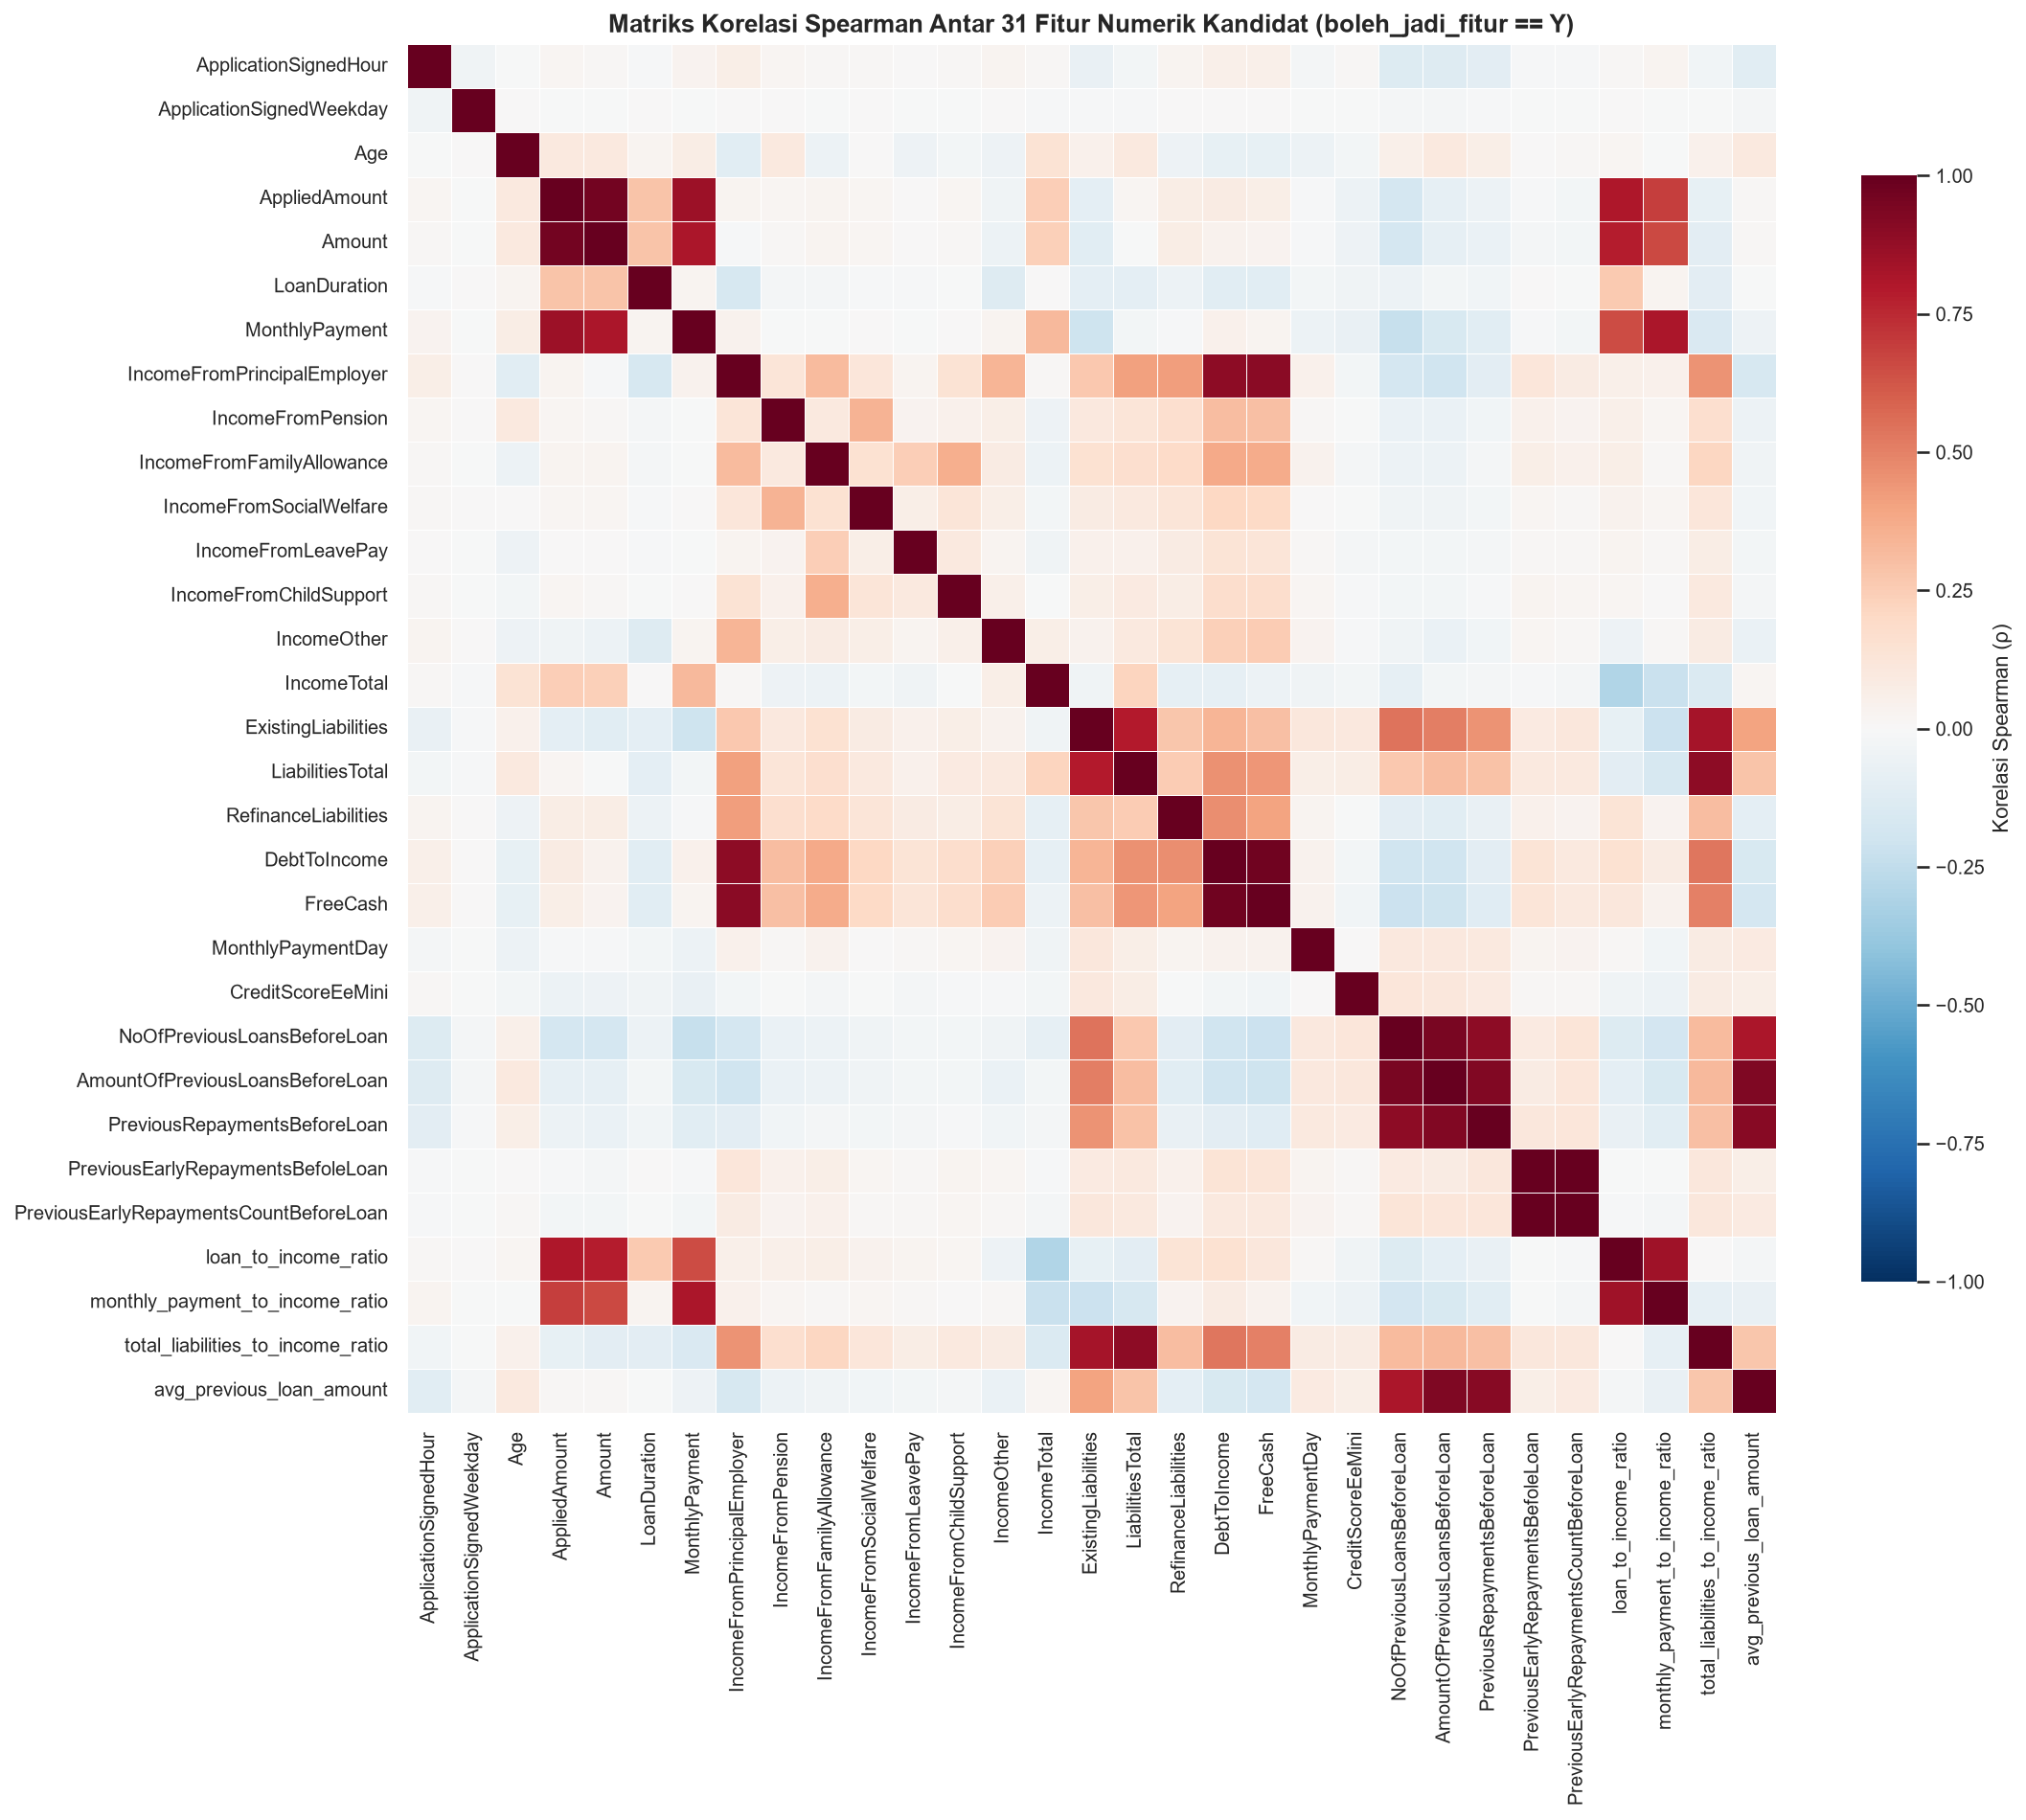

In [7]:
tbl_corr_pairs = pd.read_csv(config.TABLES_DIR / "03_high_correlation_pairs.csv")
tbl_vif = pd.read_csv(config.TABLES_DIR / "03_vif.csv")

print("=== 1. Pasangan Fitur Numerik dengan |Spearman rho| >= 0,80 (03_high_correlation_pairs.csv — 19 Pasangan) ===")
display(tbl_corr_pairs)

print("=== 2. Tabel Variance Inflation Factor / VIF (03_vif.csv — Imputasi Median Sementara Khusus VIF) ===")
display(tbl_vif)

display(Image(filename=str(config.FIGURES_DIR / "03_correlation_heatmap.png")))


### Temuan Utama Bagian F (Korelasi & Multikolinearitas)
1. **Sembilan Belas Pasangan Fitur Berkorelasi Sangat Tinggi ($|\rho_s| \ge 0{,}80$, `03_high_correlation_pairs.csv`):** Terbagi ke dalam empat gugus domain yang jelas:
   - **Gugus Riwayat Pelunasan & Pinjaman Sebelumnya:** `PreviousEarlyRepaymentsBefoleLoan` — `PreviousEarlyRepaymentsCountBeforeLoan` ($\rho_s = 0{,}9995$), `NoOfPreviousLoansBeforeLoan` — `AmountOfPreviousLoansBeforeLoan` ($\rho_s = 0{,}9495$), `AmountOfPreviousLoansBeforeLoan` — `avg_previous_loan_amount` ($\rho_s = 0{,}9328$), `AmountOfPreviousLoansBeforeLoan` — `PreviousRepaymentsBeforeLoan` ($\rho_s = 0{,}9233$), `PreviousRepaymentsBeforeLoan` — `avg_previous_loan_amount` ($\rho_s = 0{,}9129$), `NoOfPreviousLoansBeforeLoan` — `PreviousRepaymentsBeforeLoan` ($\rho_s = 0{,}8916$), dan `NoOfPreviousLoansBeforeLoan` — `avg_previous_loan_amount` ($\rho_s = 0{,}8197$). Seluruhnya bernilai `0` pada peminjam baru (`NewCreditCustomer == True`).
   - **Gugus Variabel Finansial Pra-2018:** `DebtToIncome` — `FreeCash` ($\rho_s = 0{,}9737$), `IncomeFromPrincipalEmployer` — `FreeCash` ($\rho_s = 0{,}9056$), dan `IncomeFromPrincipalEmployer` — `DebtToIncome` ($\rho_s = 0{,}8962$), karena ketiganya tercatat aktif sebelum 2018 dan bernilai `0` sejak 2018.
   - **Gugus Nominal Pinjaman & Cicilan:** `AppliedAmount` — `Amount` ($\rho_s = 0{,}9667$), `AppliedAmount` — `MonthlyPayment` ($\rho_s = 0{,}8555$), `Amount` — `MonthlyPayment` ($\rho_s = 0{,}8150$), `loan_to_income_ratio` — `monthly_payment_to_income_ratio` ($\rho_s = 0{,}8497$), `MonthlyPayment` — `monthly_payment_to_income_ratio` ($\rho_s = 0{,}8155$), dan `AppliedAmount` — `loan_to_income_ratio` ($\rho_s = 0{,}8115$).
   - **Gugus Kewajiban (*Liabilities*):** `LiabilitiesTotal` — `total_liabilities_to_income_ratio` ($\rho_s = 0{,}8913$) dan `ExistingLiabilities` — `total_liabilities_to_income_ratio` ($\rho_s = 0{,}8307$).
2. **Analisis Variance Inflation Factor (`03_vif.csv`):**
   - Tiga fitur mencatat **VIF Tinggi ($\ge 10$)**: `monthly_payment_to_income_ratio` ($	ext{VIF} = 30{,}43$, $R^2 = 0{,}9671$), `loan_to_income_ratio` ($	ext{VIF} = 29{,}38$, $R^2 = 0{,}9660$), dan `AppliedAmount` ($	ext{VIF} = 12{,}54$, $R^2 = 0{,}9202$).
   - Dua fitur mencatat **VIF Sedang ($5 - 10$)**: `Amount` ($	ext{VIF} = 8{,}37$) dan `AmountOfPreviousLoansBeforeLoan` ($	ext{VIF} = 5{,}91$).
   - **Implikasi Tahap 4:** Untuk model linier (`LogisticRegression`, `Ridge`/`Lasso`/`ElasticNet`), kita harus menyaring salah satu dari pasangan `AppliedAmount` vs `Amount` serta `monthly_payment_to_income_ratio` vs `loan_to_income_ratio`, dan cukup mempertahankan perwakilan tunggal untuk gugus riwayat pinjaman sebelumnya.

---
## Bagian G — Stabilitas Distribusi Fitur Antar-Era (*Population Stability Index* / PSI)

Untuk mengukur seberapa besar pergeseran distribusi fitur seiring waktu, kita menghitung **Population Stability Index (PSI)** untuk **44 fitur kandidat** dengan **kohort referensi `2009–2016` ($n = 31.257$)** terhadap dua periode pembanding: **kohort `2017` ($n = 17.933$)** dan **kohort `2018–2020` ($n = 108.461$)** (menggunakan bin kuantil dari kohort referensi untuk fitur numerik dan kategori tetap untuk fitur kategorikal, dengan penghalusan $\varepsilon = 10^{-4}$).

**Konvensi Kategori PSI:**
- $< 0{,}10$: *Stabil*
- $0{,}10 - 0{,}25$: *Bergeser sedang*
- $> 0{,}25$: *Bergeser besar*

=== Ringkasan Population Stability Index (PSI) — Referensi 2009–2016 vs 2017 dan 2018–2020 ===


,fitur,tipe,n_ref_2009_2016,n_2017,n_2018_2020,psi_2017,kategori_psi_2017,psi_2018_2020,kategori_psi_2018_2020,catatan_pergeseran
0,EmploymentStatus,kategorikal,31257,17933,108461,7.097963,"Bergeser besar (> 0,25)",17.685139,"Bergeser besar (> 0,25)",Pergeseran struktural kode -1 (Not set) mencap...
1,MaritalStatus,kategorikal,31257,17933,108461,7.079158,"Bergeser besar (> 0,25)",17.037584,"Bergeser besar (> 0,25)",Pergeseran struktural kode -1 (Not set) mencap...
2,CreditScoreEsMicroL,kategorikal,31257,17933,108461,4.899991,"Bergeser besar (> 0,25)",16.692581,"Bergeser besar (> 0,25)",Perubahan cakupan skoring biro kredit eksterna...
3,UseOfLoan,kategorikal,31257,17933,108461,7.114250,"Bergeser besar (> 0,25)",16.526147,"Bergeser besar (> 0,25)",Pergeseran struktural kode -1 (Not set) mencap...
4,OccupationArea,kategorikal,31257,17933,108461,5.135481,"Bergeser besar (> 0,25)",12.998574,"Bergeser besar (> 0,25)",Pergeseran struktural kode -1 (Not set) mencap...
5,IncomeFromPrincipalEmployer,numerik,31257,17933,108461,2.084032,"Bergeser besar (> 0,25)",8.282458,"Bergeser besar (> 0,25)",Perubahan pencatatan rincian pendapatan & kas ...
6,FreeCash,numerik,31257,17933,108461,2.314597,"Bergeser besar (> 0,25)",8.277491,"Bergeser besar (> 0,25)",Perubahan pencatatan rincian pendapatan & kas ...
7,DebtToIncome,numerik,31257,17933,108461,2.100708,"Bergeser besar (> 0,25)",8.275031,"Bergeser besar (> 0,25)",Perubahan pencatatan rincian pendapatan & kas ...
8,CreditScoreFiAsiakasTietoRiskGrade,kategorikal,31257,17933,108461,0.848421,"Bergeser besar (> 0,25)",2.853593,"Bergeser besar (> 0,25)",Perubahan cakupan skoring biro kredit eksterna...
9,VerificationType,kategorikal,31257,17933,108461,0.498696,"Bergeser besar (> 0,25)",2.310369,"Bergeser besar (> 0,25)","Pergeseran distribusi populasi besar (> 0,25) ..."


=== Rekapitulasi Kategori PSI pada Kohort 2017 dan Kohort 2018–2020 ===


,Kohort 2017,Kohort 2018–2020
"Bergeser besar (> 0,25)",23,30
"Stabil (< 0,10)",17,10
"Bergeser sedang (0,10-0,25)",4,4


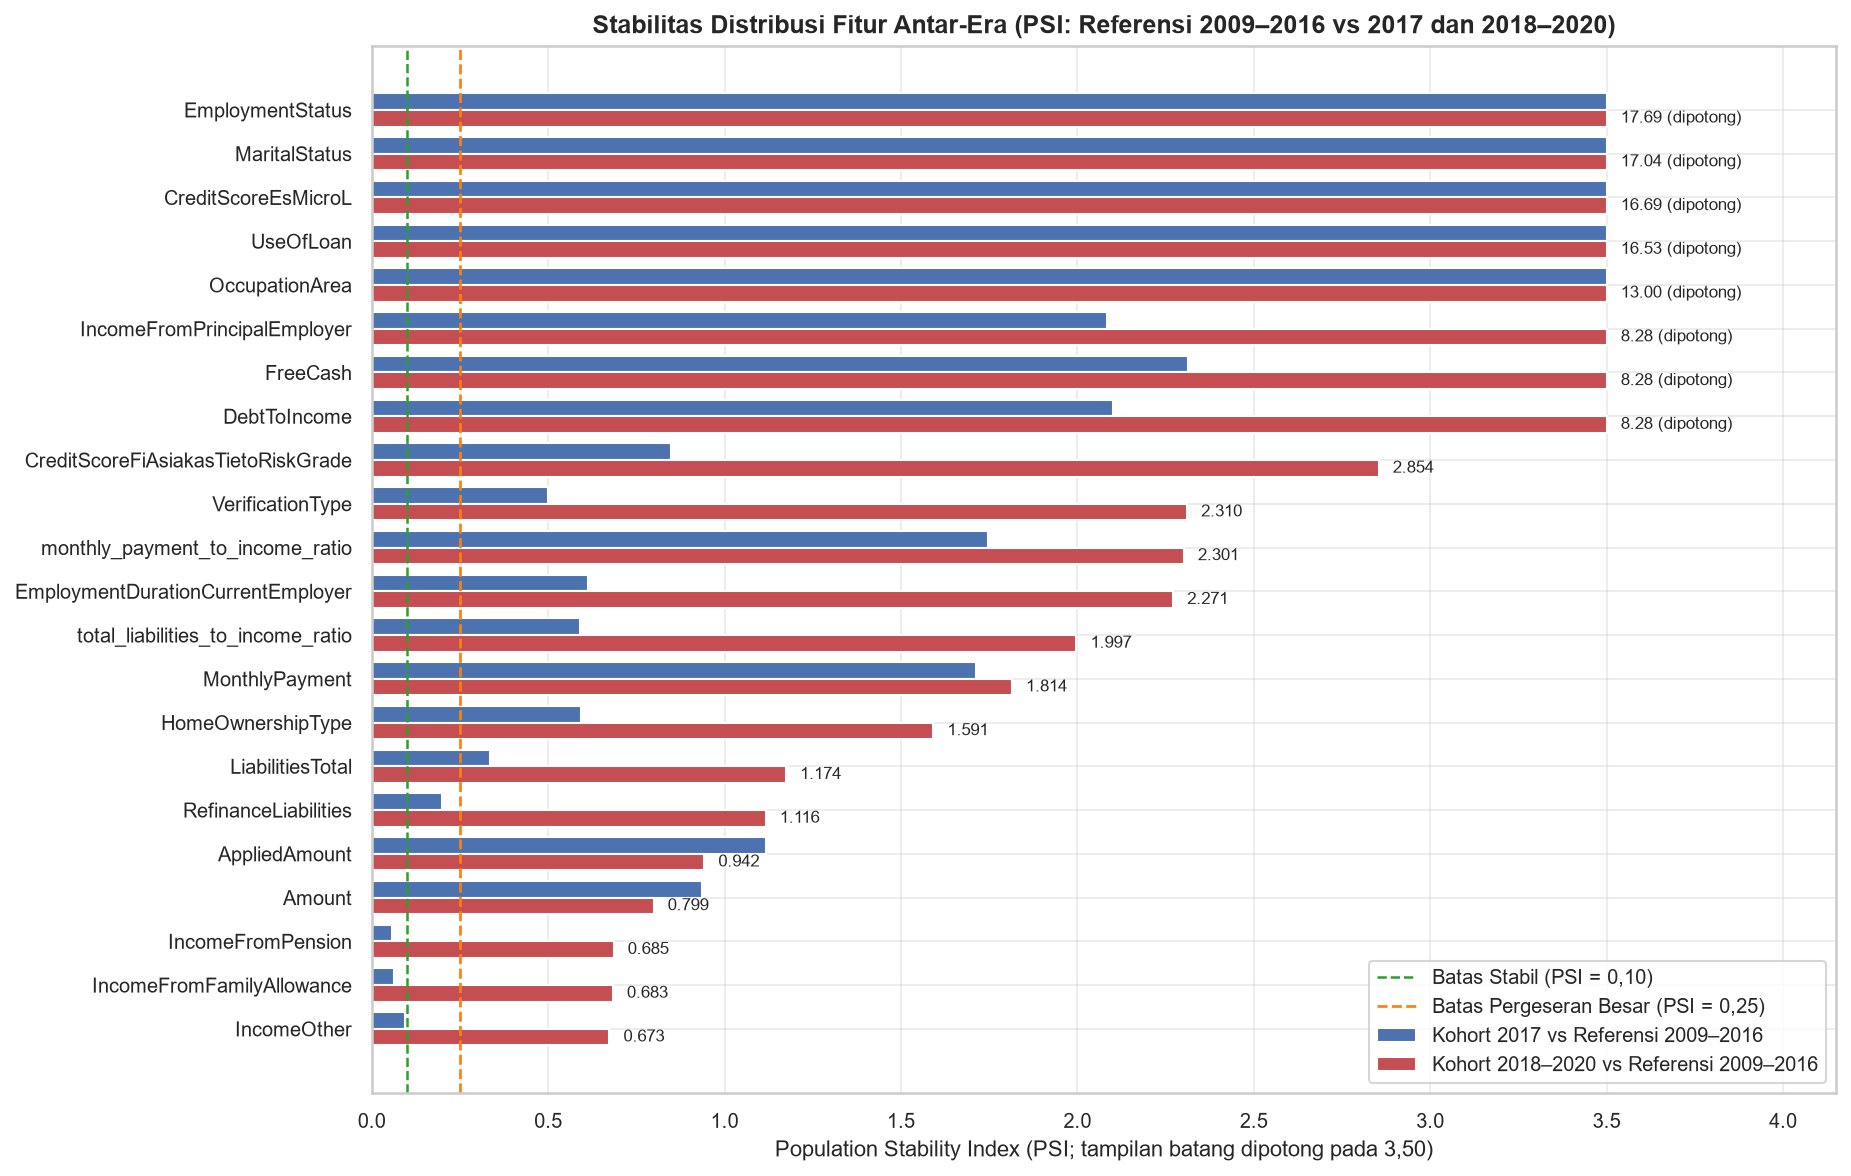

In [8]:
tbl_psi = pd.read_csv(config.TABLES_DIR / "03_psi_by_era.csv")

print("=== Ringkasan Population Stability Index (PSI) — Referensi 2009–2016 vs 2017 dan 2018–2020 ===")
display(tbl_psi)

print("=== Rekapitulasi Kategori PSI pada Kohort 2017 dan Kohort 2018–2020 ===")
rekap_psi = pd.DataFrame({
    "Kohort 2017": tbl_psi["kategori_psi_2017"].value_counts(),
    "Kohort 2018–2020": tbl_psi["kategori_psi_2018_2020"].value_counts(),
}).fillna(0).astype(int)
display(rekap_psi)

display(Image(filename=str(config.FIGURES_DIR / "03_psi_by_era.png")))


### Temuan Utama Bagian G (Stabilitas Antar-Era / PSI)
1. **Pergeseran Ekstrem ($	ext{PSI} > 8{,}0$) Akibat Perubahan Pencatatan Sistem Bondora:**
   - Lima variabel kategorikal (`EmploymentStatus` $\text{PSI}_{2018-2020} = 17{,}6851$, `MaritalStatus` $17{,}0376$, `CreditScoreEsMicroL` $16{,}6926$, `UseOfLoan` $16{,}5261$, `OccupationArea` $12{,}9986$) serta tiga variabel finansial (`IncomeFromPrincipalEmployer` $8{,}2825$, `FreeCash` $8{,}2775$, `DebtToIncome` $8{,}2750$) mengalami pergeseran distribusi masif mulai 2017 dan mencapai puncaknya pada 2018–2020.
   - Sebagaimana telah diidentifikasi secara deskriptif pada Tahap 2 (`02_sentinel_and_model_version_by_year.png`), sejak pertengahan 2017 dan hampir `100%` sejak 2018, Bondora menghentikan pengumpulan rincian pekerjaan/status pernikahan/tujuan pinjaman (diisi kode `-1 (Not set)`) serta rincian komponen pendapatan/arus kas bebas (diisi `0`).
2. **Pergeseran Besar ($0{,}25 < 	ext{PSI} \le 3{,}0$) pada 22 Fitur Lainnya:**
   - Mencakup `CreditScoreFiAsiakasTietoRiskGrade` ($2{,}8536$), `VerificationType` ($2{,}3104$), `monthly_payment_to_income_ratio` ($2{,}3013$), `EmploymentDurationCurrentEmployer` ($2{,}2712$), `MonthlyPayment` ($1{,}8142$), `HomeOwnershipType` ($1{,}5915$), `AppliedAmount` ($0{,}9421$), `Amount` ($0{,}7986$), `PreviousRepaymentsBeforeLoan` ($0{,}6224$), `Education` ($0{,}6097$), `LoanDuration` ($0{,}5946$), serta variabel riwayat pinjaman sebelumnya (`AmountOfPreviousLoansBeforeLoan` $0{,}4728$, `NoOfPreviousLoansBeforeLoan` $0{,}3144$). Secara keseluruhan, **30 dari 44 fitur kandidat** memiliki $\text{PSI}_{2018-2020} > 0{,}25$.
3. **Fitur yang Stabil ($	ext{PSI} < 0{,}10$) atau Bergeser Sedang ($0{,}10 - 0{,}25$) pada `2018–2020`:**
   - **Bergeser Sedang ($0{,}10 - 0{,}25$, 4 fitur):** `CreditScoreEeMini` ($0{,}1527$), `LanguageCode` ($0{,}1279$), `NewCreditCustomer` ($0{,}1070$), dan `Age` ($0{,}1042$).
   - **Stabil ($	ext{PSI} < 0{,}10$, 10 fitur):** `Country` ($0{,}0865$), `ApplicationSignedHour` ($0{,}0852$), `PreviousEarlyRepaymentsBefoleLoan` ($0{,}0657$), `loan_to_income_ratio` ($0{,}0502$), `IncomeTotal` ($0{,}0393$), `ApplicationSignedWeekday` ($0{,}0373$), `PreviousEarlyRepaymentsCountBeforeLoan` ($0{,}0002$), serta 3 sub-komponen pendapatan yang sejak awal mayoritas bernilai `0` (`IncomeFromLeavePay`, `IncomeFromChildSupport`, `IncomeFromSocialWelfare`).

---
## Bagian H — Analisis Waktu-ke-Default (*Kaplan–Meier Cumulative Incidence* & Uji *Log-Rank*)

Untuk memanfaatkan seluruh informasi waktu pengamatan dari `178.787` pinjaman valid (setelah mengecualikan `448` baris `Repaid` *write-off* tanpa `DefaultDate`; tidak ada baris dengan `DefaultDate < LoanDate`), kita memodelkan waktu menuju gagal bayar:
- **Kejadian (`event = 1`):** `DefaultDate` terisi ($n = 71.416$), dengan durasi $\text{duration\_months} = (\text{DefaultDate} - \text{LoanDate}) / 30{,}4375$.
- **Tersensor Kanan (`event = 0`):** `DefaultDate` kosong ($n = 107.371$). Durasi pengamatan dihitung hingga `ContractEndDate` apabila pinjaman telah lunas (`Status == 'Repaid'` dan `ContractEndDate <= REPORT_DATE`), atau hingga `REPORT_DATE` (`2021-07-20`) apabila pinjaman masih berjalan.

> **Keterangan Grafik & Tabel Kaplan–Meier:**
> **"Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung."**
>
> Dalam estimasi Kaplan–Meier ini, pinjaman yang dilunasi lebih awal (*early repayment*) atau selesai sesuai jadwal sebelum 36 bulan diperlakukan sebagai penyensoran (*cause-specific* / *non-informative right-censoring*) pada tanggal pelunasannya. Karena peminjam yang melunasi pinjaman secara penuh cenderung berisiko lebih rendah, kurva insiden kumulatif Kaplan–Meier $1 - S(t)$ sedikit lebih tinggi dibandingkan probabilitas default aktual (`rate_12m_langsung`).

Keterangan Tabel & Grafik Kaplan-Meier:
  Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung.

=== 1. Ringkasan Uji Log-Rank Multi-Kelompok (Terkoreksi Holm) ===


,variabel,n_kelompok,logrank_chi2,logrank_df,logrank_p_value,logrank_p_holm,min_km_12m,max_km_12m,min_km_24m,max_km_24m,rentang_km_12m_pp,rentang_km_24m_pp
0,Country,4,30424.6750,3,0.000000e+00,0.000000e+00,0.183364,0.723825,0.365701,0.895626,54.05,52.99
1,Rating,8,31223.7274,7,0.000000e+00,0.000000e+00,0.093506,0.654678,0.211251,0.828818,56.12,61.76
2,LoanDuration_group,5,814.8764,4,4.602125e-175,9.204249e-175,0.199878,0.338179,0.353403,0.603713,13.83,25.03
3,cohort_era,4,558.4234,3,1.037743e-120,1.037743e-120,0.251004,0.401721,0.442502,0.578168,15.07,13.57


=== 2. Tabel Number at Risk & Insiden Kumulatif 1 - S(t) pada 6, 12, 24, dan 36 Bulan ===
Keterangan: Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung.


,variabel,segmen,n_awal,n_event_total,n_at_risk_6m,n_at_risk_12m,n_at_risk_24m,n_at_risk_36m,km_incidence_6m,km_incidence_12m,km_incidence_24m,km_incidence_36m
0,Country,EE,110616,31021,81907,59158,26429,10726,0.065171,0.183364,0.365701,0.474595
1,Country,FI,41692,21142,26275,16778,4292,1419,0.177574,0.427679,0.679542,0.785520
2,Country,ES,26183,18984,15261,8094,1522,521,0.348410,0.622198,0.834230,0.897146
3,Country,SK,296,269,180,78,26,14,0.376091,0.723825,0.895626,0.938530
4,Rating,AA,6573,1186,5568,4790,1468,803,0.024072,0.093506,0.211251,0.298070
5,Rating,A,7548,1897,6275,5401,2826,1244,0.039424,0.118146,0.256520,0.348436
6,Rating,B,22565,4826,15897,11590,6280,2810,0.037125,0.131317,0.283916,0.392053
7,Rating,C,29724,8195,21860,15571,7012,2974,0.059384,0.174923,0.365899,0.476495
8,Rating,D,36715,11617,23591,15923,5805,2185,0.091129,0.254043,0.481314,0.592113
9,Rating,E,32924,14580,24472,16584,4358,1350,0.122610,0.321656,0.569641,0.682897


=== 3. Perbandingan Eksplisit Insiden Kumulatif KM (12m & 24m) vs Default Rate Horizon Langsung ===


,variabel,segmen,n_awal,km_incidence_12m,rate_12m_langsung,selisih_km12m_minus_rate12m,km_incidence_24m,rate_24m_langsung,selisih_km24m_minus_rate24m,keterangan,selisih_12m_pp,selisih_24m_pp
0,Country,EE,110616,0.183364,0.170802,0.012562,0.365701,0.320661,0.045040,Insiden kumulatif dengan pelunasan dini sebaga...,1.26,4.50
1,Country,FI,41692,0.427679,0.381511,0.046168,0.679542,0.633535,0.046007,Insiden kumulatif dengan pelunasan dini sebaga...,4.62,4.60
2,Country,ES,26183,0.622198,0.556888,0.065310,0.834230,0.711757,0.122474,Insiden kumulatif dengan pelunasan dini sebaga...,6.53,12.25
3,Country,SK,296,0.723825,0.706081,0.017744,0.895626,0.864865,0.030761,Insiden kumulatif dengan pelunasan dini sebaga...,1.77,3.08
4,Rating,AA,6573,0.093506,0.084806,0.008700,0.211251,0.187333,0.023918,Insiden kumulatif dengan pelunasan dini sebaga...,0.87,2.39
5,Rating,A,7548,0.118146,0.108612,0.009535,0.256520,0.218091,0.038428,Insiden kumulatif dengan pelunasan dini sebaga...,0.95,3.84
6,Rating,B,22565,0.131317,0.126510,0.004807,0.283916,0.256826,0.027091,Insiden kumulatif dengan pelunasan dini sebaga...,0.48,2.71
7,Rating,C,29724,0.174923,0.164280,0.010644,0.365899,0.324742,0.041157,Insiden kumulatif dengan pelunasan dini sebaga...,1.06,4.12
8,Rating,D,36715,0.254043,0.241202,0.012841,0.481314,0.424398,0.056916,Insiden kumulatif dengan pelunasan dini sebaga...,1.28,5.69
9,Rating,E,32924,0.321656,0.292597,0.029059,0.569641,0.504675,0.064966,Insiden kumulatif dengan pelunasan dini sebaga...,2.91,6.50


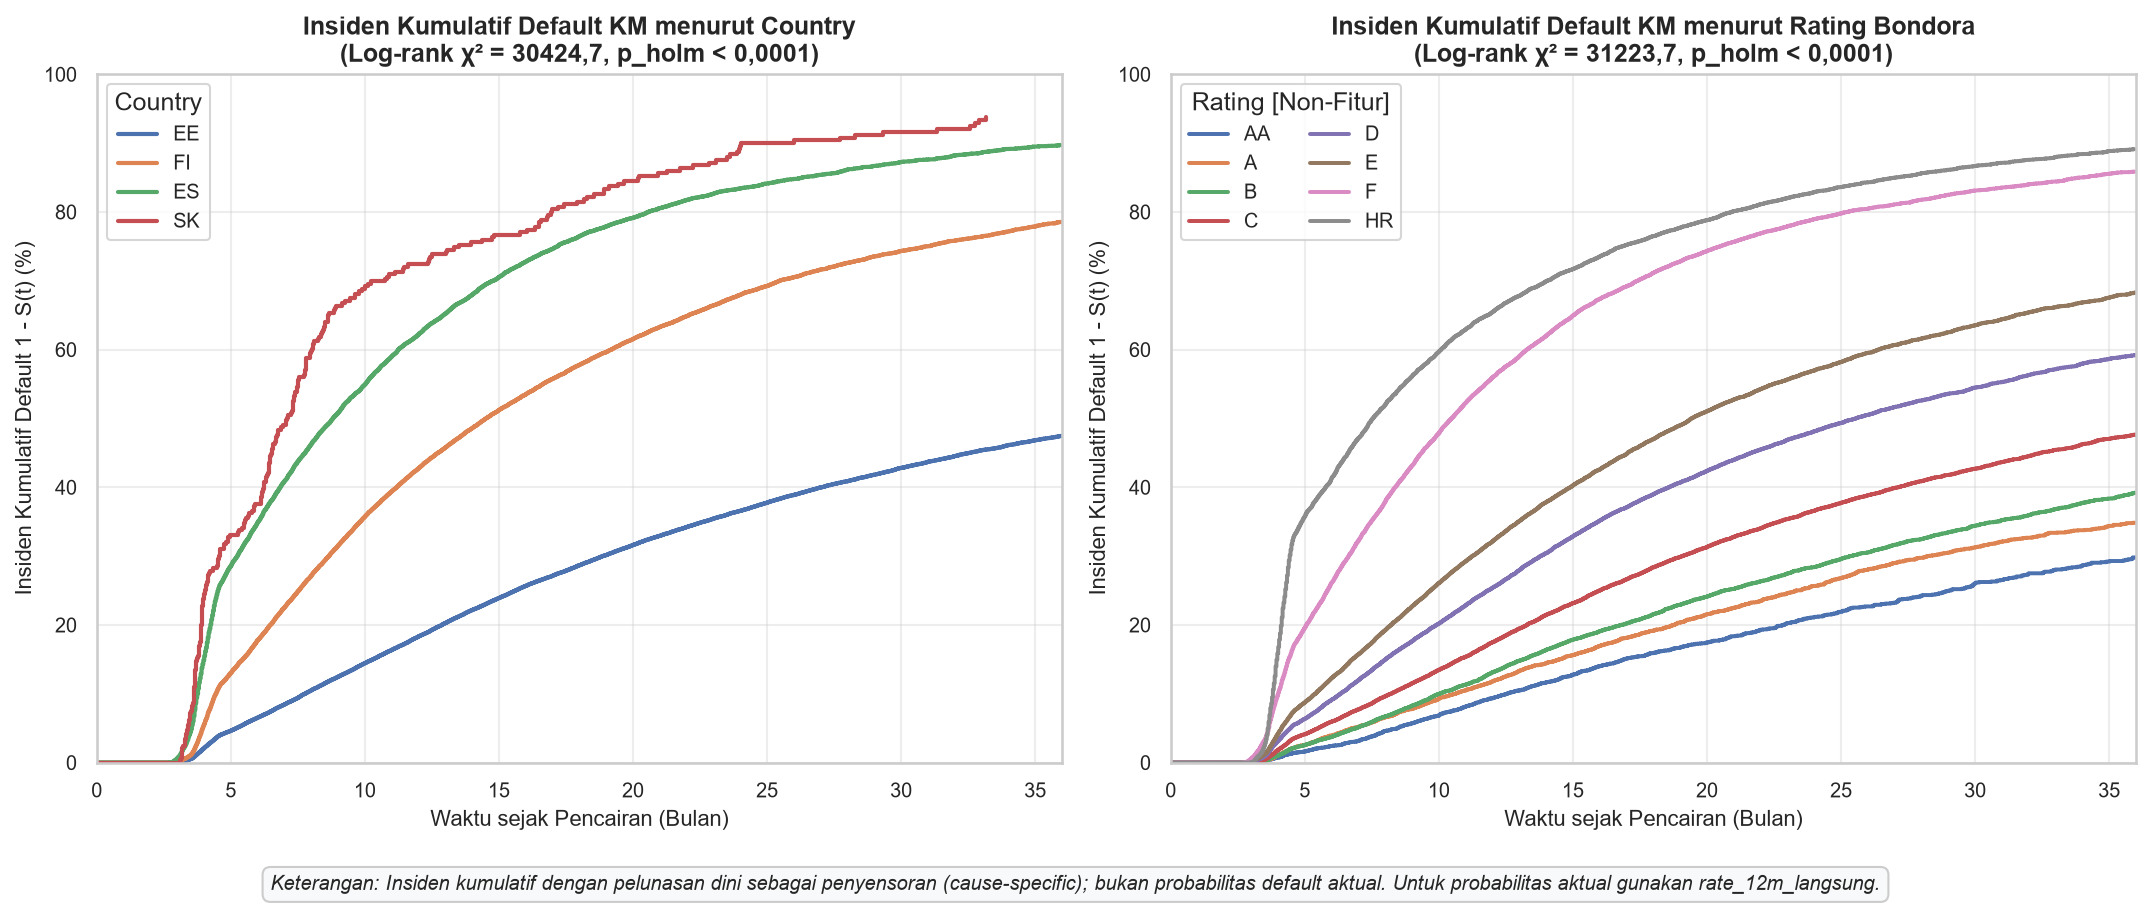

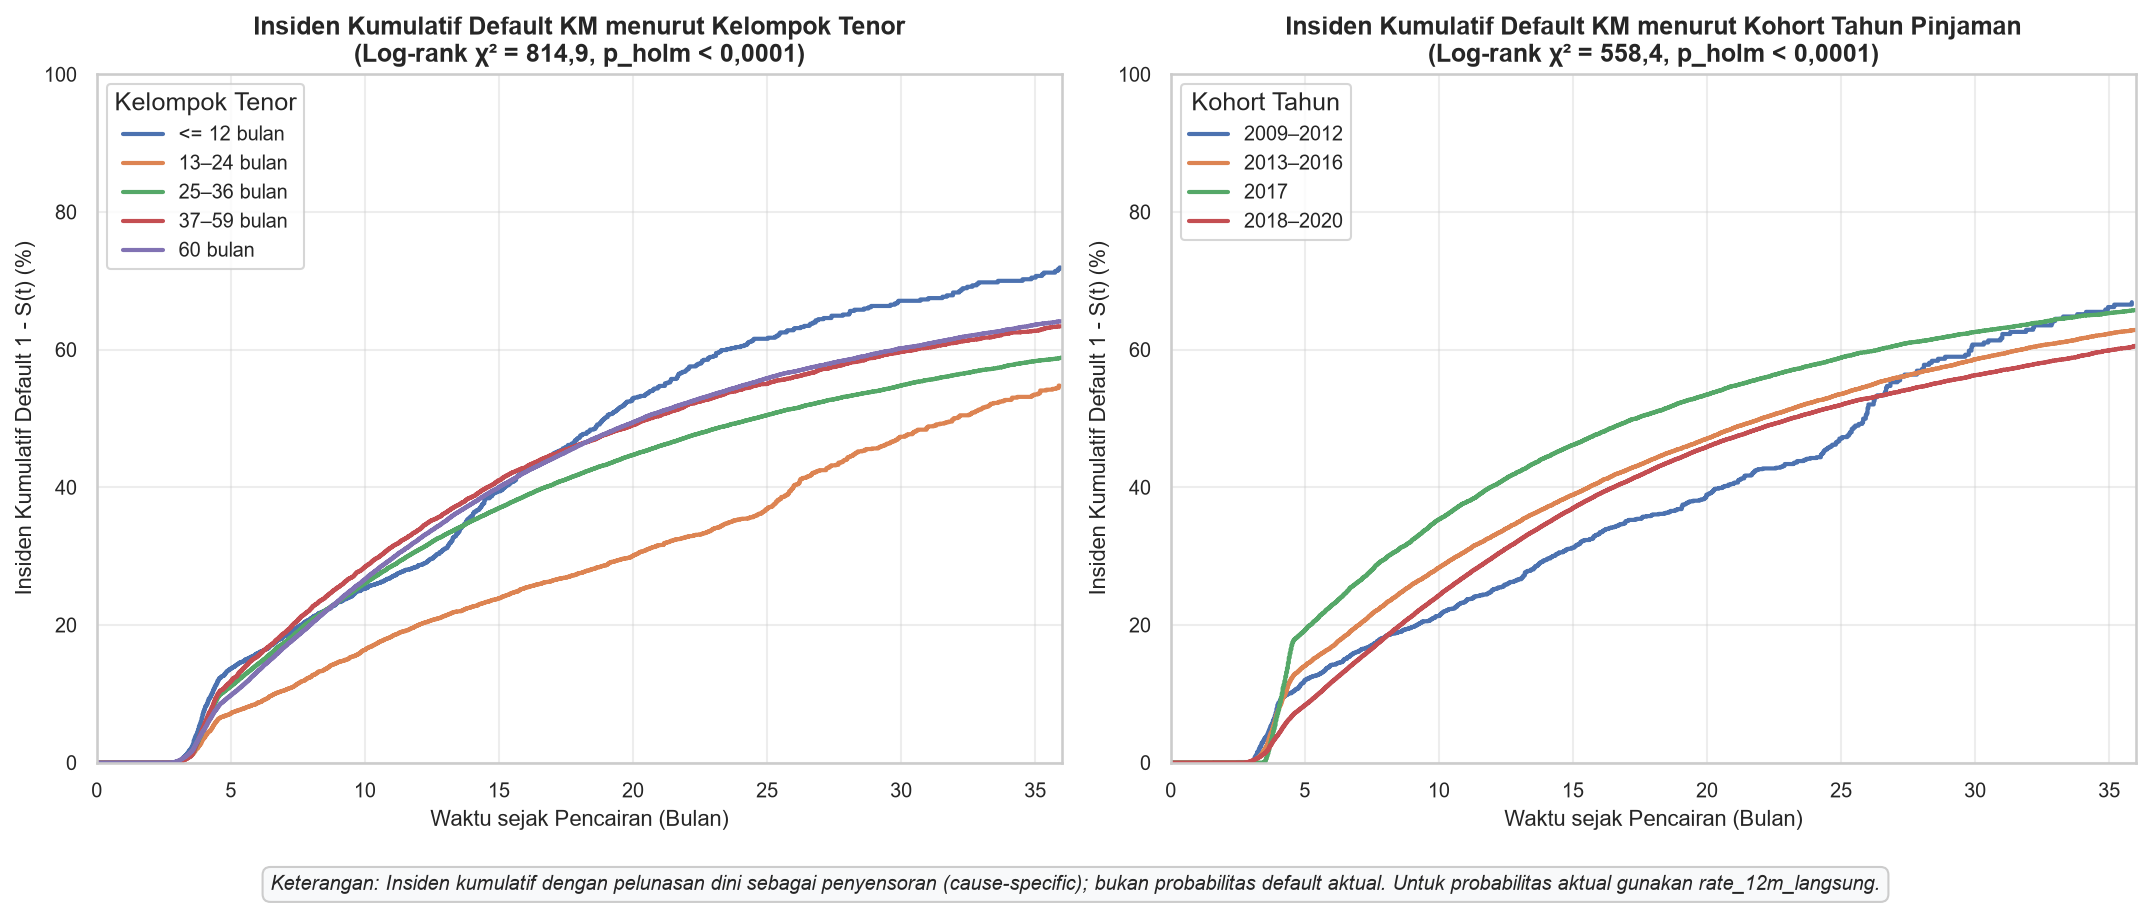

In [4]:
tbl_km = pd.read_csv(config.TABLES_DIR / "03_km_cumulative_default.csv")
print("Keterangan Tabel & Grafik Kaplan-Meier:")
print("  Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung.\n")

print("=== 1. Ringkasan Uji Log-Rank Multi-Kelompok (Terkoreksi Holm) ===")
logrank_summary = tbl_km.groupby("variabel", sort=False).agg(
    n_kelompok=("segmen", "count"),
    logrank_chi2=("logrank_chi2", "first"),
    logrank_df=("logrank_df", "first"),
    logrank_p_value=("logrank_p_value", "first"),
    logrank_p_holm=("logrank_p_holm", "first"),
    min_km_12m=("km_incidence_12m", "min"),
    max_km_12m=("km_incidence_12m", "max"),
    min_km_24m=("km_incidence_24m", "min"),
    max_km_24m=("km_incidence_24m", "max"),
).reset_index()
logrank_summary["rentang_km_12m_pp"] = ((logrank_summary["max_km_12m"] - logrank_summary["min_km_12m"]) * 100).round(2)
logrank_summary["rentang_km_24m_pp"] = ((logrank_summary["max_km_24m"] - logrank_summary["min_km_24m"]) * 100).round(2)
display(logrank_summary)

print("=== 2. Tabel Number at Risk & Insiden Kumulatif 1 - S(t) pada 6, 12, 24, dan 36 Bulan ===")
print("Keterangan: Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung.")
display(tbl_km[[
    "variabel", "segmen", "n_awal", "n_event_total",
    "n_at_risk_6m", "n_at_risk_12m", "n_at_risk_24m", "n_at_risk_36m",
    "km_incidence_6m", "km_incidence_12m", "km_incidence_24m", "km_incidence_36m"
]])

print("=== 3. Perbandingan Eksplisit Insiden Kumulatif KM (12m & 24m) vs Default Rate Horizon Langsung ===")
km_comp = tbl_km[[
    "variabel", "segmen", "n_awal", "km_incidence_12m", "rate_12m_langsung", "selisih_km12m_minus_rate12m",
    "km_incidence_24m", "rate_24m_langsung", "selisih_km24m_minus_rate24m", "keterangan"
]].copy()
km_comp["selisih_12m_pp"] = (km_comp["selisih_km12m_minus_rate12m"] * 100).round(2)
km_comp["selisih_24m_pp"] = (km_comp["selisih_km24m_minus_rate24m"] * 100).round(2)
display(km_comp)

display(Image(filename=str(config.FIGURES_DIR / "03_km_country_and_rating.png")))
display(Image(filename=str(config.FIGURES_DIR / "03_km_tenor_and_cohort.png")))

### Temuan Utama Bagian H (Waktu-ke-Default / Kaplan–Meier & Log-Rank)
1. **Signifikansi Pemisahan Kurva Survival (`Log-Rank Test`):** Keempat dimensi pembanding menunjukkan perbedaan kurva waktu-ke-default yang sangat signifikan setelah koreksi Holm ($p_{\text{holm}} \le 1{,}04 \times 10^{-120}$):
   - **`Rating`:** $\chi^2 = 31.223{,}73$ ($\text{df} = 7$, $p_{\text{holm}} < 10^{-300}$), rentang selisih insiden kumulatif antar kelas (`HR` vs `AA`) sebesar **56,12 poin persentase pada 12 bulan** (`65,47%` vs `9,35%`) dan **61,76 poin persentase pada 24 bulan** (`82,88%` vs `21,13%`).
   - **`Country`:** $\chi^2 = 30.424{,}68$ ($\text{df} = 3$, $p_{\text{holm}} < 10^{-300}$), rentang selisih insiden kumulatif (`SK`/`ES` vs `EE`) sebesar **54,05 poin persentase pada 12 bulan** (`SK` `72,38%` dan `ES` `62,22%` vs `EE` `18,34%`) dan **52,99 poin persentase pada 24 bulan** (`SK` `89,56%` dan `ES` `83,42%` vs `EE` `36,57%`).
   - **`LoanDuration_group`:** $\chi^2 = 814{,}88$ ($\text{df} = 4$, $p_{\text{holm}} = 9{,}20 \times 10^{-175}$), rentang selisih insiden kumulatif sebesar **13,83 poin persentase pada 12 bulan** (`37–59 bulan` `33,82%` vs `13–24 bulan` `19,99%`) dan **25,03 poin persentase pada 24 bulan**.
   - **`cohort_era`:** $\chi^2 = 558{,}42$ ($\text{df} = 3$, $p_{\text{holm}} = 1{,}04 \times 10^{-120}$), rentang selisih insiden kumulatif sebesar **15,07 poin persentase pada 12 bulan** (`2009–2012` `25,10%` vs `2017` `40,17%`) dan **13,57 poin persentase pada 24 bulan** (`2009–2012` `44,25%` vs `2017` `57,82%`).
2. **Penjelasan Selisih antara `km_incidence_12m` dan `rate_12m_langsung` (Bagian B):**
   - Pada hampir seluruh segmen, angka insiden kumulatif KM 12 bulan (`km_incidence_12m`) tercatat lebih tinggi sekitar **`+0,48` hingga `+6,92` poin persentase** dibandingkan `rate_12m_langsung`. Hal ini terjadi karena dua mekanisme: (a) pada estimasi KM, pinjaman yang lunas (`Repaid`) sebelum 12 bulan dikeluarkan dari penyebut *number at risk* (`event = 0` tersensor pada `ContractEndDate`), sehingga kejadian gagal bayar pada bulan-bulan berikutnya dibagi oleh penyebut aktif yang lebih kecil; sedangkan pada `rate_12m_langsung`, pinjaman yang lunas dini tetap berada di dalam penyebut populasi `observable_12m`; (b) KM mengikutsertakan pinjaman kohort pertengahan 2020–2021 hingga tanggal potong pengamatannya.
   - Fenomena yang sama terlihat jelas pada kelompok tenor **`<= 12 bulan` pada horizon 24 bulan** (`km_incidence_24m = 60,37%` vs `rate_24m_langsung = 30,18%`, selisih `+30,19` pp): karena kontrak `<= 12 bulan` yang normal sudah lunas pada bulan ke-12 (`n_at_risk` menyusut dari `9.302` menjadi `2.169` pada 12 bulan dan hanya `268` pada 24 bulan), pinjaman tenor `<= 12 bulan` yang masih tersisa di himpunan risiko setelah bulan ke-12 hampir seluruhnya adalah pinjaman bermasalah yang terlambat bayar dan akhirnya jatuh ke status default pada tahun kedua.

---
## Bagian I — Analisis Keadilan (*Fairness*) Deskriptif & Pemeriksaan Faktor Perancu (`Gender`)

Sesuai keputusan Gerbang 2, kolom **`Gender` (`boleh_jadi_fitur == 'N'`, peran `audit_fairness`) tidak digunakan sebagai fitur prediktif** di dalam model. Bagian ini menyajikan analisis transparansi deskriptif terhadap `default_12m` menurut `Gender` (menggunakan kode asli `0`, `1`, `2` dengan penanda `TODO: label resmi`), `Age_group`, dan `Country`, serta menguji apakah perbedaan tingkat gagal bayar antar kode `Gender` berasosiasi dengan variabel lain di dalam portofolio.

In [10]:
tbl_fair = pd.read_csv(config.TABLES_DIR / "03_fairness_summary.csv")

print("=== 1. Tabel Ringkasan Keadilan Deskriptif (Gender, Age_group, Country terhadap default_12m) ===")
display(tbl_fair)

# 2. Pemeriksaan Asosiasi Gender dengan Fitur Lain (Khususnya Country) pada Populasi default_12m
sub_12m = df[df["default_12m"].notna()].copy()
ct_gender_country = pd.crosstab(sub_12m["Gender"], sub_12m["Country"], margins=True)
ct_gender_country_pct = pd.crosstab(sub_12m["Gender"], sub_12m["Country"], normalize="index") * 100

cv_gender_country = compute_cramers_v(sub_12m["Gender"], sub_12m["Country"])
cv_gender_newcust = compute_cramers_v(sub_12m["Gender"], sub_12m["NewCreditCustomer"])

print(f"=== 2. Asosiasi Gender dengan Kovariat Lain ===")
print(f"- Gender vs Country           : Cramér's V = {cv_gender_country['cramers_v']:.4f} (Chi2 = {cv_gender_country['chi2']:.2f}, p < 1e-300)")
print(f"- Gender vs NewCreditCustomer : Cramér's V = {cv_gender_newcust['cramers_v']:.4f} (Chi2 = {cv_gender_newcust['chi2']:.2f})")

print("\nTabulasi Silang Jumlah Pinjaman (Gender x Country) pada Populasi Valid 12m:")
display(ct_gender_country)

print("Persentase Baris (Gender x Country, %):")
display(ct_gender_country_pct.round(2))

print("Default Rate 12m (%) menurut Gender di dalam Masing-Masing Negara (Country):")
dr_gender_within_country = sub_12m.groupby(["Country", "Gender"], observed=True).agg(
    n=("default_12m", "count"),
    default_rate_12m_pct=("default_12m", lambda s: round(float(s.mean()) * 100, 2) if len(s) > 0 else np.nan),
).unstack("Gender")
display(dr_gender_within_country)


=== 1. Tabel Ringkasan Keadilan Deskriptif (Gender, Age_group, Country terhadap default_12m) ===


,dimensi,kelompok,n,n_default_12m,default_rate_12m,ci_low_95,ci_high_95,default_rate_by_amount_12m,kelompok_acuan_terendah,selisih_mutlak_vs_acuan,rasio_vs_acuan,chi2_dimensi,p_value_dimensi,cramers_v_dimensi,catatan
0,Gender (TODO: label resmi),2,12122,6815,0.562201,0.553351,0.571012,0.554625,1,0.340918,2.5406,5373.8150,0.000000e+00,0.190342,Gender bukan fitur model (atribut_sensitif); h...
1,Gender (TODO: label resmi),(Missing),45,15,0.333333,0.213589,0.479295,0.070556,1,0.112051,1.5064,5373.8150,0.000000e+00,0.190342,Gender bukan fitur model (atribut_sensitif); h...
2,Gender (TODO: label resmi),0,91856,26474,0.288212,0.285292,0.291150,0.303911,1,0.066929,1.3025,5373.8150,0.000000e+00,0.190342,Gender bukan fitur model (atribut_sensitif); h...
3,Gender (TODO: label resmi),1,44346,9813,0.221283,0.217443,0.225170,0.243035,1,0.000000,1.0000,5373.8150,0.000000e+00,0.190342,Gender bukan fitur model (atribut_sensitif); h...
4,Age_group,< 25,12456,4272,0.342967,0.334680,0.351351,0.366957,45–54,0.069812,1.2556,216.2007,1.231534e-45,0.038180,Gender bukan fitur model (atribut_sensitif); h...
5,Age_group,25–34,40168,11740,0.292272,0.287845,0.296740,0.304796,45–54,0.019118,1.0700,216.2007,1.231534e-45,0.038180,Gender bukan fitur model (atribut_sensitif); h...
6,Age_group,>= 55,23861,6939,0.290809,0.285081,0.296605,0.312693,45–54,0.017655,1.0646,216.2007,1.231534e-45,0.038180,Gender bukan fitur model (atribut_sensitif); h...
7,Age_group,35–44,40995,11720,0.285889,0.281535,0.290282,0.288895,45–54,0.012734,1.0466,216.2007,1.231534e-45,0.038180,Gender bukan fitur model (atribut_sensitif); h...
8,Age_group,45–54,30836,8423,0.273155,0.268210,0.278156,0.286114,45–54,0.000000,1.0000,216.2007,1.231534e-45,0.038180,Gender bukan fitur model (atribut_sensitif); h...
9,Country,SK,296,209,0.706081,0.651810,0.755072,0.716014,EE,0.535280,4.1339,16687.2705,0.000000e+00,0.335368,Gender bukan fitur model (atribut_sensitif); h...


=== 2. Asosiasi Gender dengan Kovariat Lain ===
- Gender vs Country           : Cramér's V = 0.4606 (Chi2 = 62935.13, p < 1e-300)
- Gender vs NewCreditCustomer : Cramér's V = 0.1690 (Chi2 = 4237.11)

Tabulasi Silang Jumlah Pinjaman (Gender x Country) pada Populasi Valid 12m:


Country,EE,ES,FI,SK,All
Gender,,,,,
0,57766,11794,22151,145,91856
1,28431,2283,13481,151,44346
2,16,12106,0,0,12122
All,86213,26183,35632,296,148324


Persentase Baris (Gender x Country, %):


Country,EE,ES,FI,SK
Gender,,,,
0,62.89,12.84,24.11,0.16
1,64.11,5.15,30.40,0.34
2,0.13,99.87,0.00,0.00


Default Rate 12m (%) menurut Gender di dalam Masing-Masing Negara (Country):


n               default_rate_12m_pct              
Gender       0      1      2                    0      1      2
Country                                                        
EE       57766  28431     16                 18.3  14.58  18.75
ES       11794   2283  12106                56.22  49.89  56.27
FI       22151  13481   <NA>                41.39  32.83   <NA>
SK         145    151   <NA>                73.79  67.55   <NA>

### Temuan Utama Bagian I (Keadilan Deskriptif & Asosiasi `Gender` dengan `Country`)
1. **Perbedaan Tingkat Gagal Bayar 12m menurut `Gender` (Tanpa Kontrol Kovariat, `03_fairness_summary.csv`):**
   - Kode `1` (TODO: label resmi): `n = 44.346`, tingkat gagal bayar 12m terendah sebesar **`22,13%`** (CI 95%: `[21,74%, 22,52%]`, acuan rasio `1,00x`).
   - Kode `0` (TODO: label resmi): `n = 91.856`, tingkat gagal bayar 12m sebesar **`28,82%`** (CI 95%: `[28,53%, 29,12%]`, selisih `+6,69` pp, rasio `1,30x` terhadap kode `1`).
   - Kode `2` (TODO: label resmi): `n = 12.122`, tingkat gagal bayar 12m tertinggi sebesar **`56,22%`** (CI 95%: `[55,34%, 57,10%]`, selisih **`+34,09` pp**, rasio **`2,54x`** terhadap kode `1`).
   - Uji Chi-square antara `Gender` dan `default_12m` menghasilkan $\chi^2 = 5.373{,}82$ ($p < 10^{-300}$, **Cramér's $V = 0{,}1903$**).
2. **Temuan Kritis — `Gender == 2` Berasosiasi Sangat Kuat dengan Negara Spanyol (`Country == 'ES'`):**
   - Pemeriksaan tabulasi silang antara `Gender` dan `Country` mengungkapkan **Cramér's $V = 0{,}4606$** ($\chi^2 = 62.943{,}82$): dari `12.122` baris berkode `Gender == 2` pada populasi `default_12m`, sebanyak **`12.106` baris (`99,87%`) berasal dari Spanyol (`ES`)**!
   - Sebagaimana ditunjukkan pada tabel di dalam masing-masing negara (`Country`), tingkat gagal bayar 12m di Spanyol memang tinggi di semua kode `Gender` (`55,10%` pada kode `0`, `55,95%` pada kode `1`, dan `56,24%` pada kode `2`). Dengan demikian, tingginya tingkat gagal bayar agregat pada kode `Gender == 2` (`56,22%`) bukan bukti diskriminasi, melainkan artefak komposisi data di mana kode `Gender == 2` hampir seluruhnya tercatat pada pinjaman pasar Spanyol (`ES`).
3. **Penegasan Kebijakan Pemodelan & Etika:** Sesuai keputusan Gerbang 2, `Gender` (`boleh_jadi_fitur = N`) **tidak diikutsertakan sebagai fitur model** pada Tahap 4. Namun, karena `Country` dan `LanguageCode` berasosiasi kuat dengan kode `Gender == 2`, evaluasi keadilan pasca-pemodelan (*post-hoc fairness audit*) pada Tahap 4 wajib memeriksa metrik paritas/kalibrasi model baik secara agregat maupun **di dalam masing-masing negara (`within-Country`)**.

---
## Bagian J — Ringkasan Temuan Diagnostic Analytics & Implikasi untuk Tahap 4–5

Berikut adalah **13 butir temuan diagnostik utama** berdasarkan seluruh tabel (`reports/tables/03_*.csv`) dan grafik (`reports/figures/03_*.png`) yang telah diverifikasi (serta disiapkan untuk **deck laporan (PPT)**):

### (a) Efek Bias Seleksi dan Label Horizon (`03_horizon_label_summary.csv`, `03_default_rate_horizon_by_segment.csv`)
1. **Reduksi Bias Seleksi Kohort Tahunan:** Penggunaan target berhorizon tetap 12 bulan (`default_12m`, $n = 148.369$ valid dari $148.783$ `observable_12m`) menurunkan angka gagal bayar agregat dari `63,28%` (*resolved lifetime* Tahap 2, $n = 113.560$, $\text{default} = 71.864$) menjadi **`29,06%`** (dan **`45,55%`** pada horizon 24 bulan `default_24m`, $n = 97.878$). Pada kohort 2014–2019, `rate_12m` berada di rentang **`27,04%` hingga `36,53%`**, mengeliminasi lonjakan semu `64,88%` (2018) dan `70,37%` (2019) pada *resolved lifetime* (`03_horizon_default_rate_by_year.png`).
2. **Penyempitan Drastis Selisih Antar Kelompok Tenor (`LoanDuration_group`):** Pada *resolved lifetime* Tahap 2 ($n = 113.560$, $\text{default} = 71.864$), tingkat gagal bayar per kelompok tenor adalah `<= 12 bulan` **`27,49%`** ($n = 7.424$, $\text{default} = 2.041$), `13–24 bulan` **`36,65%`** ($n = 7.428$, $\text{default} = 2.722$), `25–36 bulan` **`65,21%`** ($n = 36.114$, $\text{default} = 23.551$), `37–59 bulan` **`66,59%`** ($n = 8.207$, $\text{default} = 5.465$), dan `60 bulan` **`70,03%`** ($n = 54.387$, $\text{default} = 38.085$) — rentang selisih `<= 12 bulan` vs `60 bulan` sebesar **42,53 poin persentase**. Dengan `default_12m` ($n = 148.369$, $\text{default} = 43.117$), tingkat gagal bayar menjadi **`22,00%`** (`<= 12 bulan`, Perubahan 12m vs Lifetime: **`-5,49` pp**), **`18,63%`** (`13–24 bulan`, **`-18,02` pp**), **`28,45%`** (`25–36 bulan`, **`-36,77` pp**), **`31,77%`** (`37–59 bulan`, **`-34,82` pp**), dan **`31,01%`** (`60 bulan`, **`-39,01` pp**) — **menyempitkan selisih `<= 12 bulan` vs `60 bulan` menjadi 9,02 poin persentase** (`03_default_rate_horizon_tenor_dan_demografi.png`).
3. **Kalibrasi & Benchmark `ProbabilityOfDefault` Bondora (`03_rating_vs_observed_12m.csv`, `03_benchmark_auc.csv`):** Terhadap `default_12m`, urutan tingkat gagal bayar teramati per kelas `Rating` monoton sempurna dari `AA` (`8,48%`, PD `5,21%`) hingga `HR` (`58,54%`, PD `49,69%`), dengan rasio realisasi ÷ PD pada kelas menengah `B`, `C`, `D`, dan `E` sangat dekat di rentang **`1,01x`–`1,11x`**. Secara keseluruhan ($n = 145.730$), `ProbabilityOfDefault` mencapai **ROC-AUC = `0,6998`** (CI 95%: `[0,6975, 0,7026]`), dengan AUC per era sebesar `0,7155` (`<= 2016`), `0,7506` (`2017`), dan `0,6870` (`>= 2018`).

### (b) Pendorong Utama Default (`03_hypothesis_tests.csv`, `03_driver_ranking.csv`)
4. **Dominasi Dimensi Geografis & Riwayat Pinjaman Sebelumnya:** Fitur dengan asosiasi terkuat terhadap `default_12m` adalah `LanguageCode` ($\text{IV} = 0{,}5428$, Cramér's $V = 0{,}3357$) dan `Country` ($\text{IV} = 0{,}5383$, Cramér's $V = 0{,}3354$), di mana tingkat gagal bayar 12m merentang dari `17,08%` (`EE`) hingga `38,15%` (`FI`), `55,69%` (`ES`), dan `70,61%` (`SK`). Di luar geografi, pendorong paling konsisten adalah status peminjam baru `NewCreditCustomer` ($\text{IV} = 0{,}1224$, $V = 0{,}1559$; peminjam baru `35,21%` vs berulang `20,92%`), `MonthlyPayment` ($\text{IV} = 0{,}1219$, $\text{AUC} = 0{,}5793$), `NoOfPreviousLoansBeforeLoan` ($\text{IV} = 0{,}1199$, $\text{AUC} = 0{,}5974$), dan `AmountOfPreviousLoansBeforeLoan` ($\text{IV} = 0{,}1190$, $\text{AUC} = 0{,}5892$).
5. **Efek Penanda Negara pada Skor Biro Kredit Lokal:** `CreditScoreEeMini` tampak memiliki $\text{IV} = 0{,}4288$ secara agregat semata-mata karena bin `(Missing)` mengidentifikasi pinjaman non-Estonia (`FI`/`ES`/`SK`); pada baris yang terisi (`n = 80.641`), daya pisahnya hanya $\text{AUC} = 0{,}5574$.

### (c) Stabilitas Antar-Era & Pergeseran Pencatatan (`03_psi_by_era.csv`, `03_driver_ranking.csv`)
6. **Pergeseran Distribusi Ekstrem ($\text{PSI} > 8{,}0$) pada Kohort `2018–2020`:** Terhadap referensi `2009–2016`, lima kolom kategorikal (`EmploymentStatus` $\text{PSI} = 17{,}69$, `MaritalStatus` $17{,}04$, `CreditScoreEsMicroL` $16{,}69$, `UseOfLoan` $16{,}53$, `OccupationArea` $13{,}00$) dan tiga kolom finansial (`IncomeFromPrincipalEmployer` $8{,}28$, `FreeCash` $8{,}28$, `DebtToIncome` $8{,}28$) mengalami pergeseran masif, disertai runtuhnya IV kolom-kolom tersebut menjadi `0,0000` (atau `0,0119` untuk `CreditScoreEsMicroL`) pada Era 2 (`2018–2020`).
7. **Pembaruan Peran Indikator Missing (`schema.json`, `leakage_audit.csv`):** Sesuai keputusan yang telah disetujui, ketiga kolom indikator `MonthlyPayment_missing`, `PreviousRepaymentsBeforeLoan_missing`, dan `CreditScoreEsMicroL_missing` telah diubah menjadi `boleh_jadi_fitur = 'N'` dengan peran `proxy_era` sehingga jumlah fitur kandidat resmi menjadi **44 fitur**.

### (d) Waktu-ke-Default (`03_km_cumulative_default.csv`)
8. **Kurva Insiden Kumulatif Kaplan–Meier ($1 - S(t)$):** Uji *log-rank* multi-kelompok terkoreksi Holm menunjukkan pemisahan sangat signifikan ($p_{\text{holm}} \le 1{,}04 \times 10^{-120}$) pada `Rating` ($\chi^2 = 31.223{,}73$), `Country` ($\chi^2 = 30.424{,}68$), `LoanDuration_group` ($\chi^2 = 814{,}88$), dan `cohort_era` ($\chi^2 = 558{,}42$). Pada bulan ke-36, insiden kumulatif gagal bayar mencapai `47,46%` di `EE`, `78,55%` di `FI`, `89,71%` di `ES`, dan `93,85%` di `SK` (`03_km_country_and_rating.png`). *Keterangan: "Insiden kumulatif dengan pelunasan dini sebagai penyensoran (cause-specific); bukan probabilitas default aktual. Untuk probabilitas aktual gunakan rate_12m_langsung."*

### (e) Pengembalian Pinjaman (`03_return_ratio_drivers.csv`)
9. **Faktor yang Berasosiasi dengan `return_ratio`:** Pada subset *resolved* ($n = 113.560$), di luar variabel era pra-2018 (`IncomeFromPrincipalEmployer`, `FreeCash`, `DebtToIncome`), `return_ratio` berasosiasi negatif dengan durasi tenor (`LoanDuration` $\rho_s = -0{,}1874$), beban cicilan (`MonthlyPayment` $\rho_s = -0{,}1209$), dan pokok pinjaman (`AppliedAmount` $\rho_s = -0{,}1179$, `Amount` $\rho_s = -0{,}1116$). Median `return_ratio` tercatat di atas par (`1,0276`) di Estonia (`EE`), sedangkan di `SK` (`0,2173`) dan pasar lainnya berada jauh di bawah `1,00`.

### (f) Keadilan Deskriptif (`03_fairness_summary.csv`)
10. **Efek Komposisi Geografis pada `Gender`:** Tingkat gagal bayar 12m tertinggi pada `Gender == 2` (`56,22%`, $n = 12.122$) dibandingkan `Gender == 0` (`28,82%`) dan `Gender == 1` (`22,13%`) berasosiasi sangat kuat dengan `Country` (Cramér's $V = 0{,}4606$), di mana **`99,87%` (`12.106` dari `12.122`) baris `Gender == 2` berasal dari Spanyol (`ES`)**. Di dalam negara Spanyol sendiri, tingkat gagal bayar 12m hampir identik di ketiga kode (`55,10%` pada kode `0`, `55,95%` pada kode `1`, dan `56,24%` pada kode `2`).

### (g) Implikasi Langsung untuk Tahap 4 (Predictive Analytics) & Tahap 5 (Prescriptive Analytics)
11. **Peringatan Seleksi Fitur & Pencegahan Kebocoran Data:** Seluruh nilai IV dan AUC univariat pada Tahap 3 bersifat eksploratif pada populasi penuh; pada Tahap 4, penyaringan fitur, imputasi, dan *encoding* **wajib dihitung ulang hanya pada *training set***.
12. **Penanganan Multikolinearitas (`03_high_correlation_pairs.csv`, `03_vif.csv`) & Fitur Tak Stabil:**
    - Untuk model linier di Tahap 4, saring fitur dengan $\text{VIF} \ge 10$ (`monthly_payment_to_income_ratio` $\text{VIF} = 30{,}43$, `loan_to_income_ratio` $29{,}38$, `AppliedAmount` $12{,}54$), pilih salah satu dari pasangan kolinear `Amount` vs `AppliedAmount` ($\rho_s = 0{,}9667$) dan `LanguageCode` vs `Country` ($V > 0{,}335$), serta reduksi redundansi pada gugus riwayat pinjaman sebelumnya (`NoOfPreviousLoansBeforeLoan`, `AmountOfPreviousLoansBeforeLoan`, `avg_previous_loan_amount`, `PreviousRepaymentsBeforeLoan`, $\rho_s \ge 0{,}8197$).
    - Lakukan uji ablasi terhadap 4 kolom berkode `-1 (Not set)` (`UseOfLoan`, `MaritalStatus`, `EmploymentStatus`, `OccupationArea`) serta 4 kolom dengan pergeseran era ekstrem (`DebtToIncome`, `FreeCash`, `IncomeFromPrincipalEmployer`, `CreditScoreEsMicroL`) agar model tetap andal pada kohort terbaru (`>= 2018`).
13. **Rekomendasi Desain Validasi Berbasis Waktu (*Temporal Validation*) & Optimasi Portofolio:**
    - Mengingat pergeseran distribusi yang nyata antara kohort pra-2018 dan pasca-2018 ($\text{PSI} > 0{,}25$ pada 30 dari 44 fitur kandidat) serta batas observabilitas 12 bulan hingga `2020-07-20`, Tahap 4 direkomendasikan menggunakan **`default_12m` sebagai target klasifikasi utama** dengan skema **pembagian latih/validasi/uji berbasis waktu (*time-based split*)**, serta membandingkan ROC-AUC dan kalibrasi model terhadap *benchmark* `ProbabilityOfDefault` Bondora pada periode uji yang sama.
    - Pada Tahap 5 (*Prescriptive Analytics*), alokasi portofolio perlu memperhitungkan perbedaan tajam antara distribusi `default_12m` dan `return_ratio` lintas negara (`EE` vs `FI`/`ES`/`SK`) serta membatasi paparan pada segmen tenor panjang dan pasar dengan median `return_ratio` rendah.